In [4]:
'''
check out eff predictions on april's eff data
from each fold of nn saved separately
'''

"\ncheck out eff predictions on april's eff data\nfrom each fold of nn saved separately\n"

In [1]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import precision_recall as pr
import gc  # garbage collector
import review_findings_functions as rff
import os
import importlib
import implantation_functions as imp

Matplotlib is building the font cache; this may take a moment.


In [2]:
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [ ]:
'''waaa'''

In [3]:
df_implants_neg = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_neg/df_implants_neg")
df_implants_pos = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_pos/df_implants_pos")


In [ ]:
#okay we gotta fix stuff a little and also only pos ran
#note - did this all for pos, then later did the same for neg

In [4]:
path = "/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_pos/predsarrays_4/"
for file in os.listdir(path):
    newfile = file[14:]
    os.rename(path+file,path+newfile)

In [ ]:
#now we average them?

In [139]:
!mkdir "/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_neg/predsarrays_average/"

In [140]:
savedir = "/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_neg/predsarrays_average/"

In [141]:
paths = ["/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_neg/predsarrays_0/",
         "/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_neg/predsarrays_1/",
         "/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_neg/predsarrays_2/",
         "/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_neg/predsarrays_3/",
         "/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_neg/predsarrays_4/"]
for i, file in enumerate(os.listdir(paths[0])):
    arrays = []
    for path in paths:
        arrays.append(np.load(path+file))
    average = np.average(arrays, axis=0)
    np.save(savedir+file, average)


In [143]:
average.shape

(9339120, 6)

In [ ]:
#okay now running varthresh to match them

In [338]:
!ls /lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_neg/predsarrays_average/df_matched_thr_*

/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_neg/predsarrays_average/df_matched_thr_0.6
/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_neg/predsarrays_average/df_matched_thr_0.7
/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_neg/predsarrays_average/df_matched_thr_0.8
/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_neg/predsarrays_average/df_matched_thr_0.85
/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_neg/predsarrays_average/df_matched_thr_0.9
/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_neg/predsarrays_average/df_matched_thr_0.95
/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_neg/predsarrays_average/df_matched_thr_0.97
/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_neg/predsarrays_average/df_match

In [5]:
def get_efficiency(df, df_implant, distance_threshold, posneg):
    df_cut = df[df['dist_to_implant']<=distance_threshold]
    df_cut = df_cut[df_cut['type']==posneg]
    df_cut.drop_duplicates(subset=["filename", "quad", "type","row_from_implant", "col_from_implant"], inplace=True)
    return len(df_cut),len(df_implant)

In [77]:
df.iloc[0]

Unnamed: 0.1                                                  0
Unnamed: 0                                                    0
filename               ztf_20221020138241_000686_zi_c05_x_0000.
quad                                                          1
type                                                        pos
row_from_nn                                                41.6
col_from_nn                                          548.939394
detection_size                                              165
closest_x                                                 559.0
closest_y                                                2317.0
Diff                                                   0.060606
brightness_ranking                                            7
quadrant                                                      1
num_in_file_in_star                                        70.0
dup_indices                                                  []
is_smaller_dup                          

In [107]:
# def adjust_num_all_retrieved(dfold, posneg):
#     '''
#     going to say that the duplicates where there is pos next to neg
#     doesn't count for the number of all retrieved
#     NOTE only works if iloc=loc
#     '''
#     df = dfold.copy()
#     todrop = []
#     if posneg=='pos':
#         opposite='neg'
#     elif posneg=='neg':
#         opposite='pos'
#     for i, row in df.iterrows():
#         # print(i)
#         # break
#         if row['type']==opposite:
#             for j, otherrow in df.iterrows():
#                 if otherrow['closest_x']==row['closest_x'] and otherrow['closest_y']==row['closest_y']:
#                     if otherrow['type']==posneg:
#                         if np.sqrt(((otherrow['row_from_nn']-row['row_from_nn'])**2)+((otherrow['col_from_nn']-row['col_from_nn'])**2))<40:
#                             todrop.append(i)
#     df.drop(todrop)
#     return df, len(df)

In [88]:
len(df)

1268

In [105]:
df

,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,...,brightness_ranking,quadrant,num_in_file_in_star,dup_indices,is_smaller_dup,dist_to_implant,row_from_implant,col_from_implant,A_from_implant,sig_from_implant
0,0,0,ztf_20221020148032_000686_zg_c02_x_0001.,1,pos,38.714286,240.071429,42,250.0,1761.0,...,6,1,10.0,[],0.0,0.294508,49.0,250.0,1.50,4.0
1,1,1,ztf_20221020148032_000686_zg_c02_x_0001.,1,pos,42.061728,476.086420,81,487.0,435.0,...,1,1,12.0,[],0.0,0.942243,53.0,486.0,10.00,5.0
2,2,2,ztf_20221020148032_000686_zg_c02_x_0001.,1,pos,46.745455,1430.381818,55,1441.0,1579.0,...,2,1,6.0,[],0.0,1.398583,58.0,1441.0,1.20,5.0
3,3,3,ztf_20221020148032_000686_zg_c02_x_0001.,1,pos,71.750000,2256.916667,24,2266.0,1067.0,...,9,1,4.0,[],0.0,0.950146,82.0,2266.0,5.00,4.0
4,4,4,ztf_20221020148032_000686_zg_c02_x_0001.,1,pos,85.644068,2954.305085,59,2964.0,425.0,...,3,1,5.0,[],0.0,1.389831,97.0,2964.0,1.50,7.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1263,1263,1263,ztf_20221020294271_000449_zr_c04_x_0004.,3,neg,2376.250000,2028.350000,20,2038.0,1087.0,...,0,3,22.0,[],0.0,11.755212,2398.0,2038.0,2.00,5.0
1264,1264,1264,ztf_20221020294271_000449_zr_c04_x_0004.,3,neg,2401.161290,2028.387097,62,2038.0,1087.0,...,0,3,22.0,[],0.0,13.166982,2398.0,2038.0,2.00,5.0
1265,1265,1265,ztf_20221020294271_000449_zr_c04_x_0004.,3,neg,2455.254237,2557.593220,59,2568.0,2214.0,...,7,3,7.0,[],0.0,13.260478,2452.0,2568.0,2.00,5.0
1266,1266,1266,ztf_20221020294271_000449_zr_c04_x_0004.,3,neg,2513.800000,1150.200000,5,1161.0,296.0,...,2,3,8.0,[],0.0,71.804457,2452.0,1161.0,1.15,6.0


In [108]:
newdf, num = adjust_num_all_retrieved(df, 'pos')

In [109]:
print(num, len(df))

1268 1268


In [6]:
def plot_precision_recall_from_eff_data(test_name, df_implants_pos, df_implants_neg,spacing="thresh", threshes = [ "0.5","0.6","0.7","0.8","0.85","0.9","0.95", "0.98","0.99","0.999","0.9999"], subset=None, combine_transients=False, title=None):
     #["0.2","0.3","0.4","0.5","0.6","0.7",
    threshold=20
    precisions_pos = np.zeros(len(threshes))
    recalls_pos = np.zeros(len(threshes))
    precisions_neg = np.zeros(len(threshes))
    recalls_neg = np.zeros(len(threshes))
    if subset!=None:
                df_implants_pos = df_implants_pos[df_implants_pos['A_from_implant']>=(1+subset)]
                df_implants_neg = df_implants_neg[df_implants_neg['A_from_implant']<=(1-subset)]
    for i, thr in enumerate(threshes):
        for posneg in ["pos", "neg"]:#,"neg"]:
            df = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_"+posneg+"/predsarrays_"+test_name+"/df_matched_thr_"+thr)
            if combine_transients==True:
                bothpath = ("/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_"+posneg+"/df_both_matched_thr_"+thr)
                if os.path.isfile(bothpath):
                    df = pd.read_csv(bothpath)
                else: 
                    df = make_transient_detections_df(df)
                    df.to_csv(bothpath)
                
            if subset!=None:
                # df_implants_pos = df_implants_pos[df_implants_pos['A_from_implant']>=(1+subset)]
                # df_implants_neg = df_implants_neg[df_implants_neg['A_from_implant']<=(1-subset)]
                ignore_mask_pos = (np.abs(df['dist_to_implant'])<25)*(df['A_from_implant']<(1+subset))
                ignore_mask_neg = (np.abs(df['dist_to_implant'])<25)*(df['A_from_implant']>(1-subset))
                if posneg=='pos':
                    df = df[~ignore_mask_pos]
                else:
                    df = df[~ignore_mask_neg]
            if combine_transients==True:
                newposneg = 'both'
            else:
                newposneg = posneg
                
            if posneg=="pos":

                
                cut_len, implant_len = get_efficiency(df, df_implants_pos, threshold, newposneg)
                # print(posneg, thr, len(df), cut_len, cut_len/len(df_implants_pos))
                precision = pr.precision(num_true_retrieved=cut_len, num_all_retrieved=len(df))
                # print(precision)
                recall = pr.recall(num_true_retrieved=cut_len, num_all_true=len(df_implants_pos))
                # print(recall)
                precisions_pos[i]=precision
                recalls_pos[i]=recall
            else:          
                cut_len, implant_len = get_efficiency(df, df_implants_neg, threshold, newposneg)
                precision = pr.precision(num_true_retrieved=cut_len, num_all_retrieved=len(df))
                recall = pr.recall(num_true_retrieved=cut_len, num_all_true=len(df_implants_neg))
                precisions_neg[i]=precision
                recalls_neg[i]=recall
    if spacing!="thresh":
        threshes = np.array(threshes).astype(float)
    plt.plot(threshes, precisions_pos, label="Precision, Brightening", linewidth=3, c="#cc79a7")
    plt.plot(
        threshes,
        precisions_neg,
        label="Precision, Dimming",
        linewidth=3,
        linestyle="dashed",
        c="#cc79a7",
    )
    plt.plot(threshes, recalls_pos, label="Recall, Brightening", linewidth=3, c="#009e73")
    plt.plot(
        threshes,
        recalls_neg,
        label="Recall, Dimming",
        linewidth=3,
        linestyle="dashed",
        c="#009e73",
    )
    if type(threshes[0])==str:
        plt.axvline("0.99", label='chosen threshold')
    else:
        plt.axvline(0.99, label='chosen threshold')
    plt.legend(fontsize=18)
    if title==None:
        plt.title(
        "Precision and Recall Curves from Eff Data for Brightening and Dimming Transients: "+test_name+", with subset >"+str(subset), fontsize=18)
    else:
        plt.title(title, fontsize=18)
    plt.xlabel("Threshold", fontsize=18)
    plt.ylabel("Precision and Recall", fontsize=18)
    
    # plt.ylim(0.15, 1.01)
    plt.tick_params(axis="both", labelsize=18)
    plt.show()
    return precisions_pos, recalls_pos, precisions_neg, recalls_neg

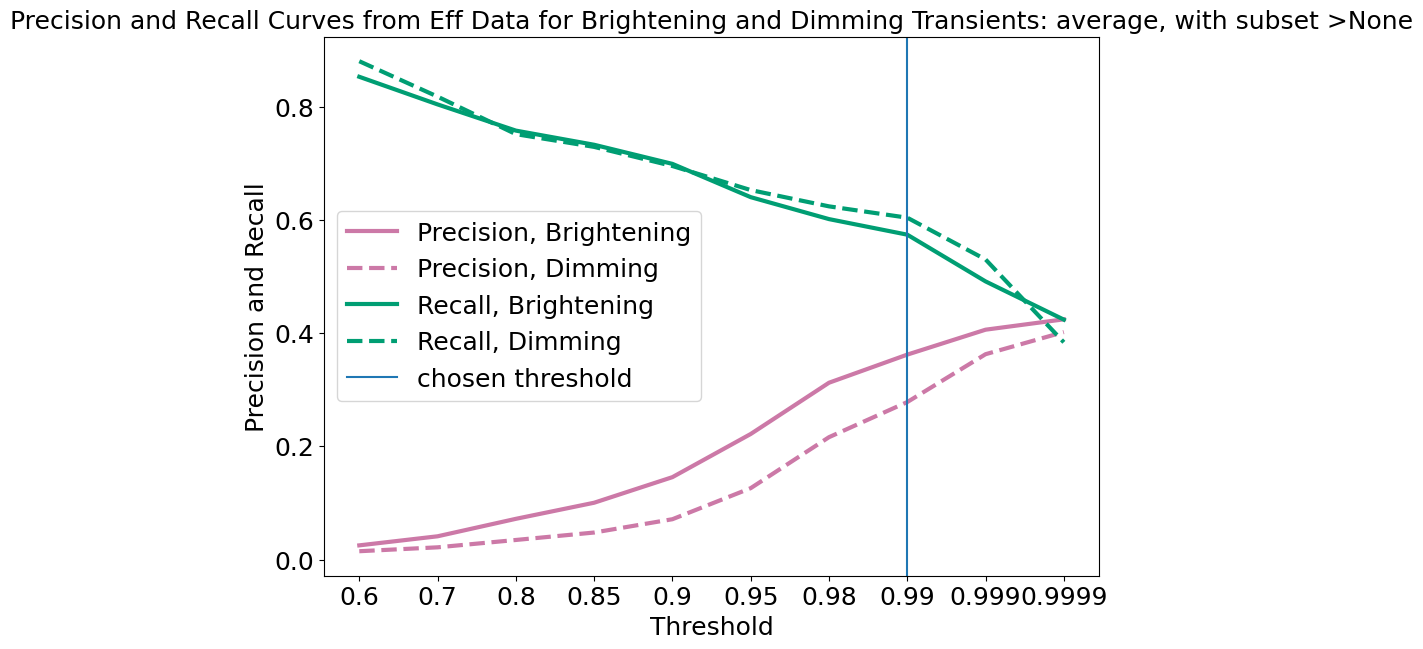

(array([0.02521816, 0.04122323, 0.07204851, 0.10048011, 0.14564878,
        0.22183709, 0.31233766, 0.36198738, 0.40599174, 0.42428035]),
 array([0.8525 , 0.80375, 0.7575 , 0.7325 , 0.69875, 0.64   , 0.60125,
        0.57375, 0.49125, 0.42375]),
 array([0.01486267, 0.02174853, 0.03472383, 0.04786928, 0.07136439,
        0.1262089 , 0.21620451, 0.27822581, 0.36270317, 0.40183246]),
 array([0.88   , 0.8175 , 0.75125, 0.72875, 0.695  , 0.6525 , 0.62375,
        0.60375, 0.53   , 0.38375]))

In [349]:
plot_precision_recall_from_eff_data("average", df_implants_pos, df_implants_neg,spacing='thresh', combine_transients=False, title=None)

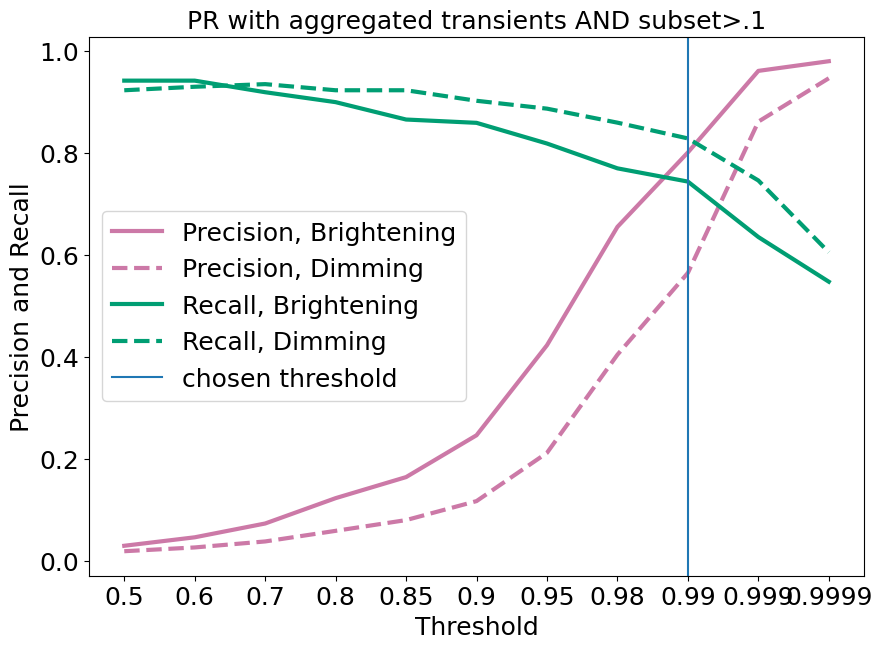

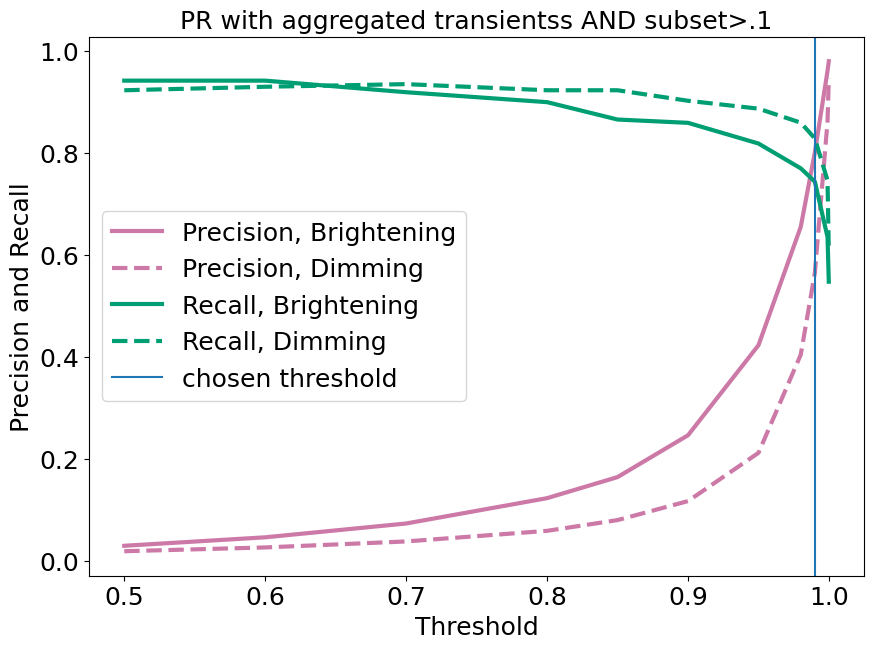

(array([0.0289942 , 0.04561183, 0.07270392, 0.12243094, 0.16374808,
        0.24581784, 0.42246438, 0.65469613, 0.8006993 , 0.96068796,
        0.97965116]),
 array([0.94155844, 0.94155844, 0.91883117, 0.89935065, 0.86525974,
        0.85876623, 0.81818182, 0.76948052, 0.74350649, 0.63474026,
        0.54707792]),
 array([0.01831389, 0.02572393, 0.03749655, 0.05829353, 0.07936743,
        0.11664075, 0.21130221, 0.40387722, 0.56440281, 0.86111111,
        0.94623656]),
 array([0.92268041, 0.92955326, 0.9347079 , 0.92268041, 0.92268041,
        0.90206186, 0.88659794, 0.85910653, 0.82817869, 0.74570447,
        0.604811  ]))

In [357]:
plot_precision_recall_from_eff_data("average", df_implants_pos, df_implants_neg,spacing='thresh', combine_transients=True, title='PR with aggregated transients AND subset>.1', subset=.1)
plot_precision_recall_from_eff_data("average", df_implants_pos, df_implants_neg,spacing='new', combine_transients=True, title='PR with aggregated transientss AND subset>.1', subset=.1)

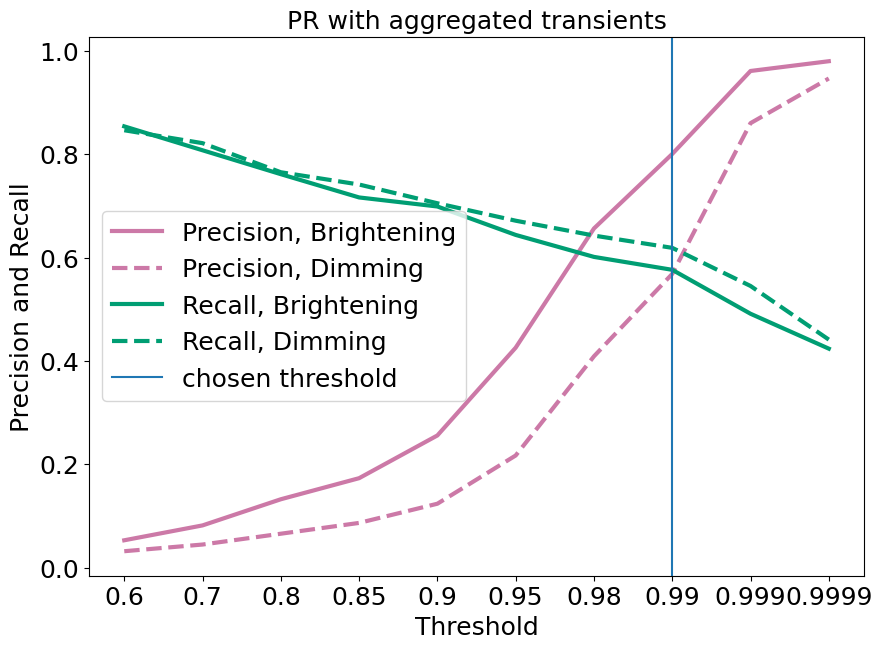

(array([0.05303619, 0.08181358, 0.1323913 , 0.1731641 , 0.25583524,
        0.42561983, 0.65620737, 0.80034722, 0.9608802 , 0.97976879]),
 array([0.85375, 0.8075 , 0.76125, 0.71625, 0.69875, 0.64375, 0.60125,
        0.57625, 0.49125, 0.42375]),
 array([0.03187532, 0.04481583, 0.06573577, 0.08664524, 0.12376564,
        0.2170574 , 0.4089101 , 0.56831228, 0.85996055, 0.9463807 ]),
 array([0.84625, 0.82125, 0.765  , 0.74125, 0.705  , 0.67125, 0.6425 ,
        0.61875, 0.545  , 0.44125]))

In [352]:
plot_precision_recall_from_eff_data("average", df_implants_pos, df_implants_neg,spacing='thresh', combine_transients=True, title='PR with aggregated transients')

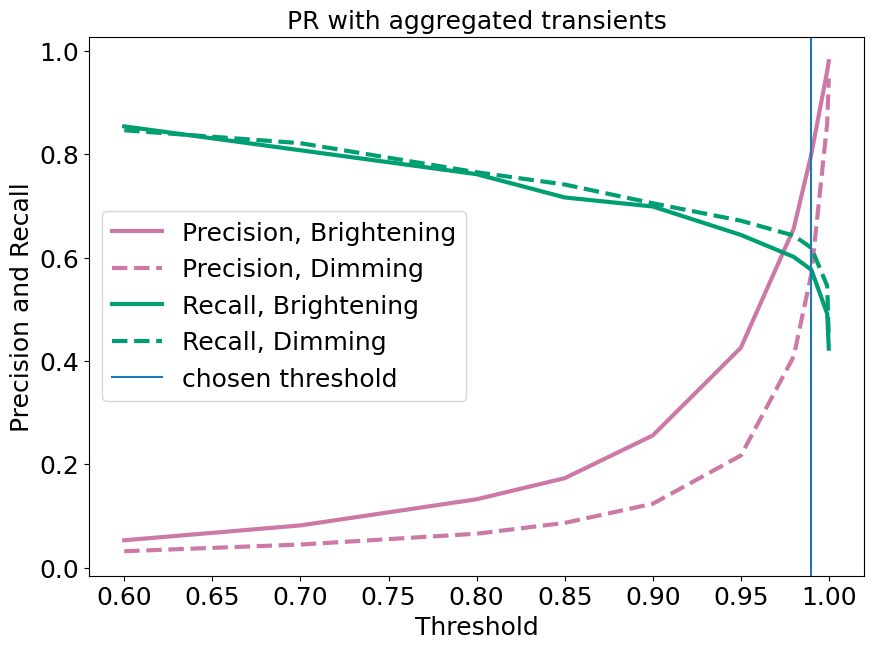

(array([0.05303619, 0.08181358, 0.1323913 , 0.1731641 , 0.25583524,
        0.42561983, 0.65620737, 0.80034722, 0.9608802 , 0.97976879]),
 array([0.85375, 0.8075 , 0.76125, 0.71625, 0.69875, 0.64375, 0.60125,
        0.57625, 0.49125, 0.42375]),
 array([0.03187532, 0.04481583, 0.06573577, 0.08664524, 0.12376564,
        0.2170574 , 0.4089101 , 0.56831228, 0.85996055, 0.9463807 ]),
 array([0.84625, 0.82125, 0.765  , 0.74125, 0.705  , 0.67125, 0.6425 ,
        0.61875, 0.545  , 0.44125]))

In [353]:
plot_precision_recall_from_eff_data("average", df_implants_pos, df_implants_neg,spacing='new', combine_transients=True, title='PR with aggregated transients')

In [342]:
plot_precision_recall_from_eff_data("average", df_implants_pos, df_implants_neg,spacing='new', combine_transients=True)
# plot_precision_recall_from_eff_data("average", df_implants_pos, df_implants_neg,spacing='thresh', combine_transients=True)

KeyboardInterrupt: 

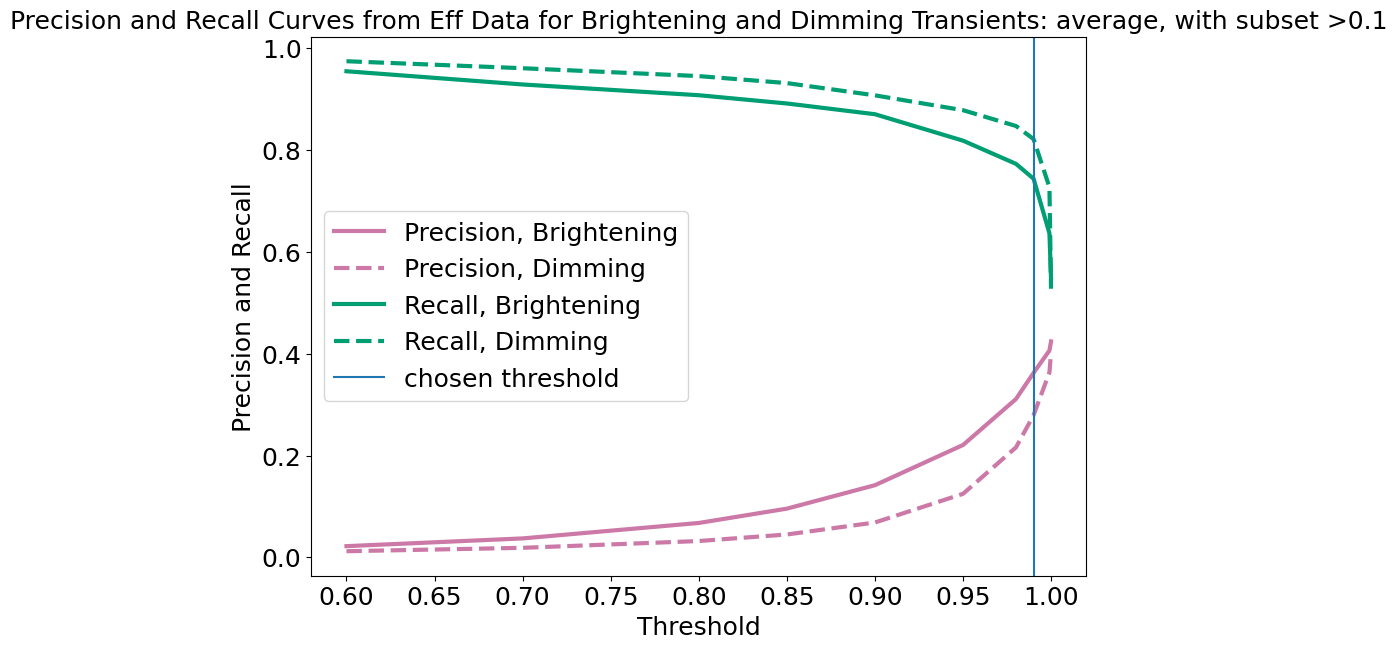

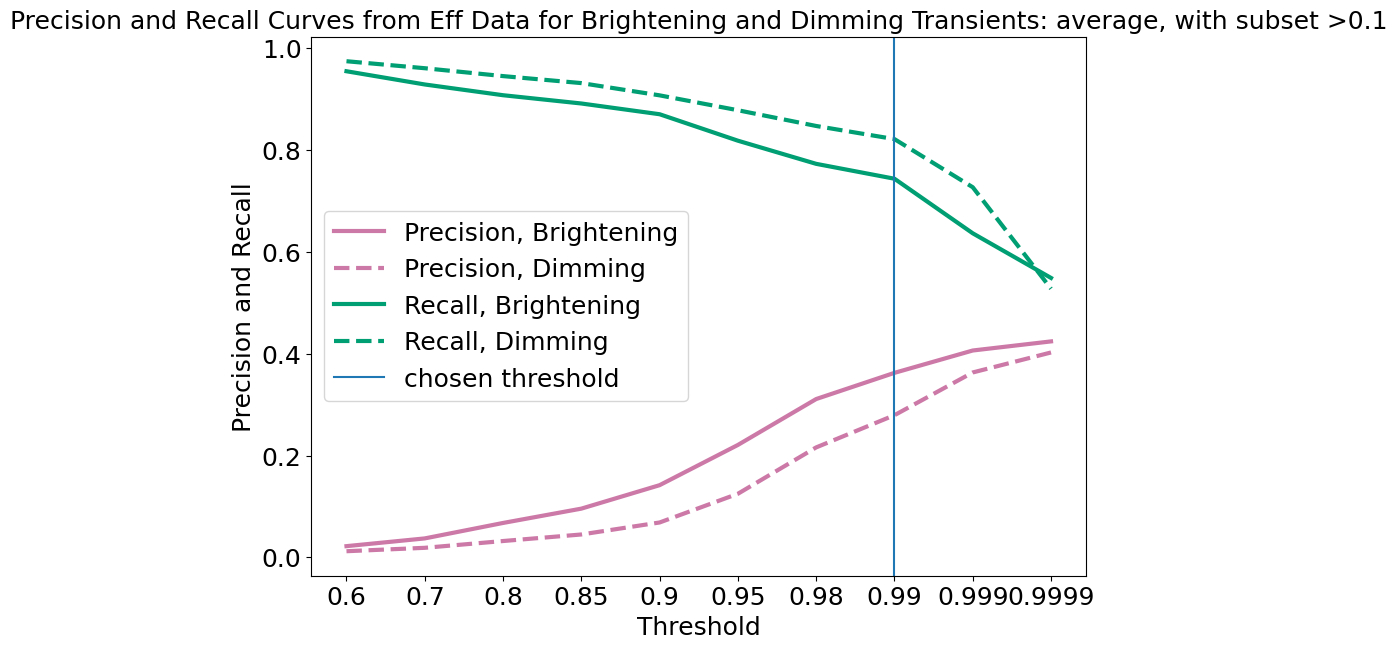

(array([0.02205303, 0.03724686, 0.06759371, 0.0957113 , 0.14179894,
        0.22076216, 0.3109079 , 0.36234177, 0.40621762, 0.42409034]),
 array([0.95454545, 0.92857143, 0.90746753, 0.89123377, 0.87012987,
        0.81818182, 0.77272727, 0.74350649, 0.63636364, 0.5487013 ]),
 array([0.01209806, 0.01879055, 0.03210741, 0.04497552, 0.06852693,
        0.12490834, 0.21594393, 0.27920561, 0.36309013, 0.40235911]),
 array([0.9742268 , 0.9604811 , 0.94501718, 0.93127148, 0.90721649,
        0.87800687, 0.84707904, 0.82130584, 0.72680412, 0.52749141]))

In [350]:
plot_precision_recall_from_eff_data("average", df_implants_pos, df_implants_neg,spacing='new', subset=.1)
plot_precision_recall_from_eff_data("average", df_implants_pos, df_implants_neg,spacing='thresh', subset=.1)

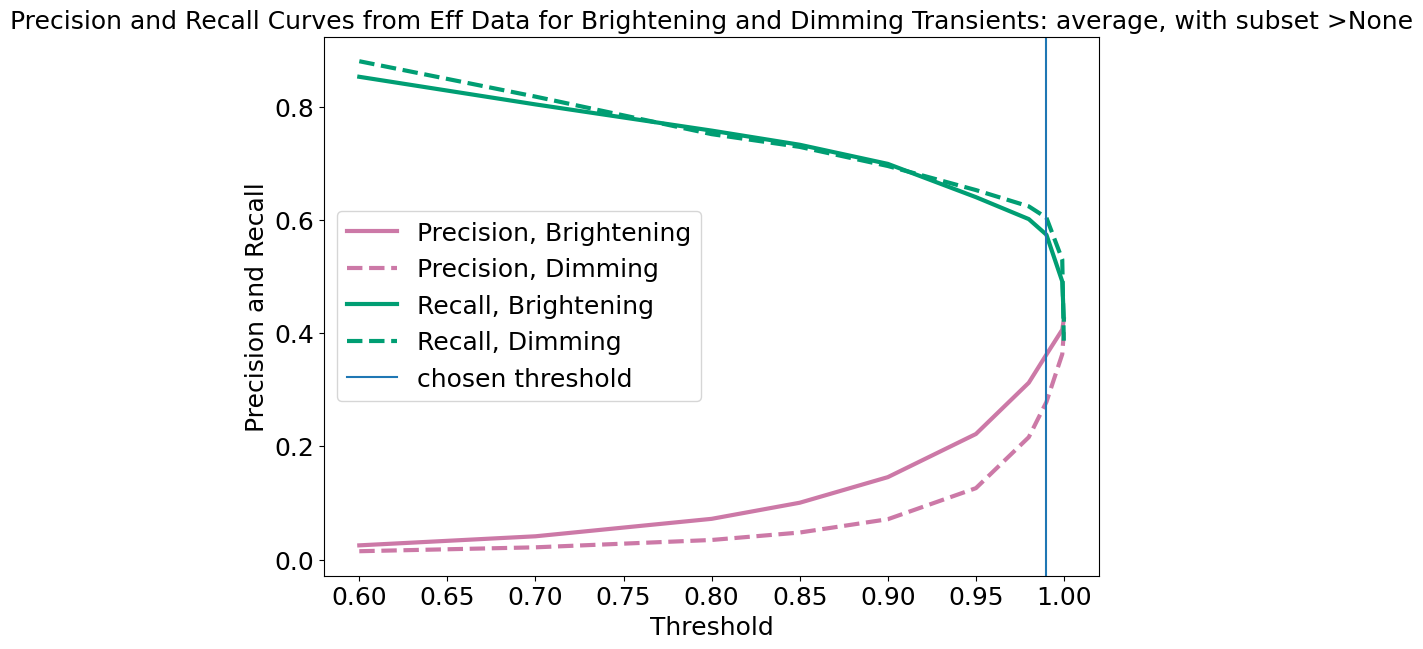

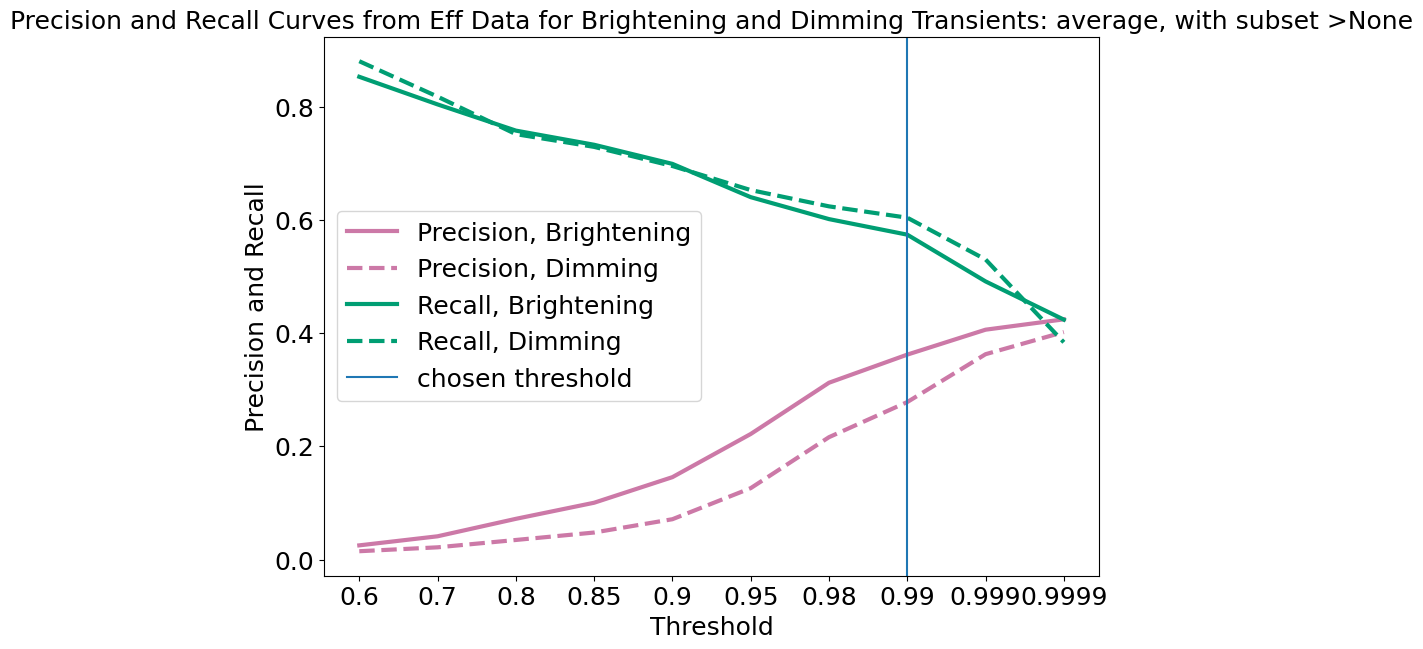

(array([0.02521816, 0.04122323, 0.07204851, 0.10048011, 0.14564878,
        0.22183709, 0.31233766, 0.36198738, 0.40599174, 0.42428035]),
 array([0.8525 , 0.80375, 0.7575 , 0.7325 , 0.69875, 0.64   , 0.60125,
        0.57375, 0.49125, 0.42375]),
 array([0.01486267, 0.02174853, 0.03472383, 0.04786928, 0.07136439,
        0.1262089 , 0.21620451, 0.27822581, 0.36270317, 0.40183246]),
 array([0.88   , 0.8175 , 0.75125, 0.72875, 0.695  , 0.6525 , 0.62375,
        0.60375, 0.53   , 0.38375]))

In [351]:
plot_precision_recall_from_eff_data("average", df_implants_pos, df_implants_neg,spacing='new')
plot_precision_recall_from_eff_data("average", df_implants_pos, df_implants_neg,spacing='thresh')

In [28]:
df = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_pos/predsarrays_average/df_matched_thr_0.99")

In [146]:
len(df)

1268

(array([279.,   0.,   0., 269.,   0.,   0., 266.,   0.,   0., 231.]),
 array([0. , 0.3, 0.6, 0.9, 1.2, 1.5, 1.8, 2.1, 2.4, 2.7, 3. ]),
 <BarContainer object of 10 artists>)

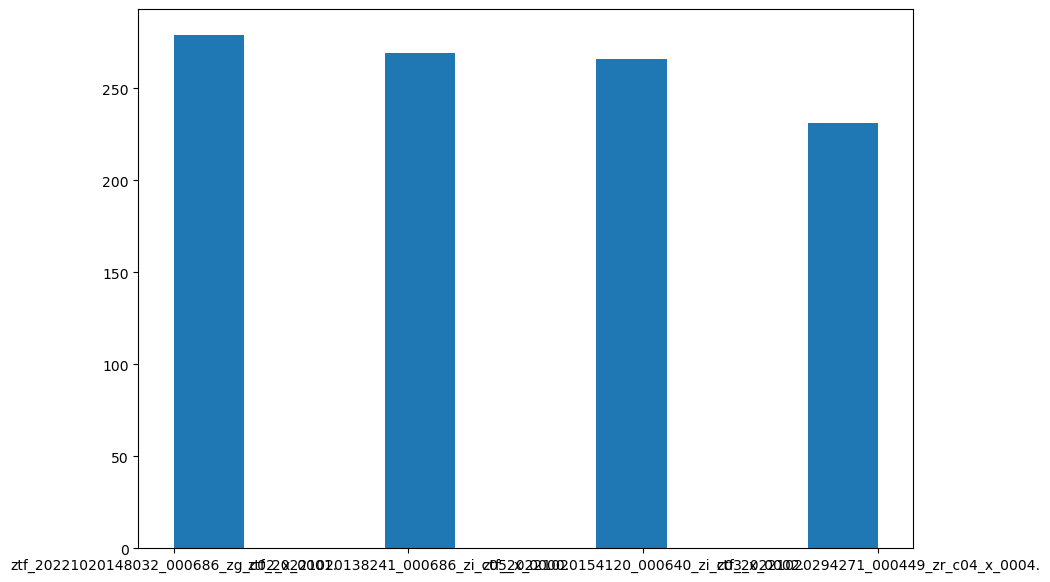

In [87]:
plt.hist(df[df['dist_to_implant']<20]['filename'])

In [56]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

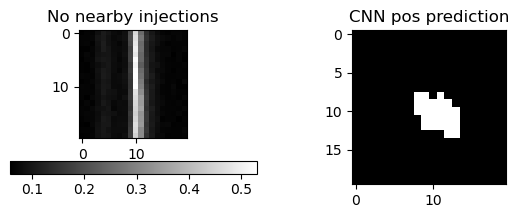

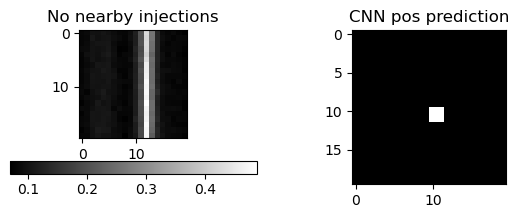

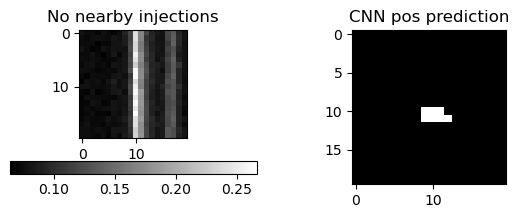

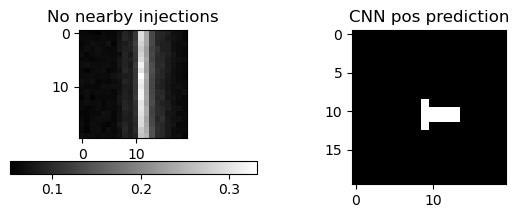

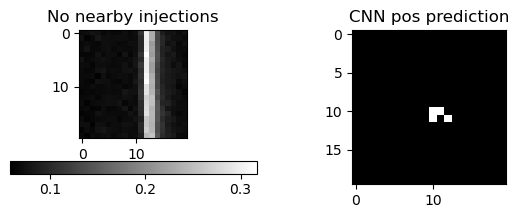

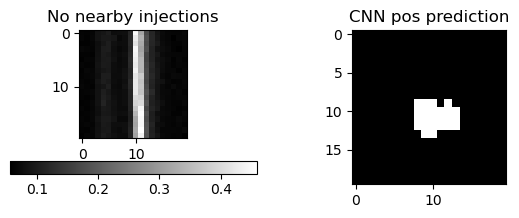

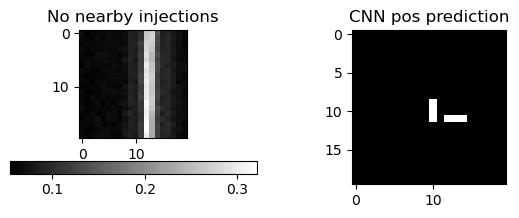

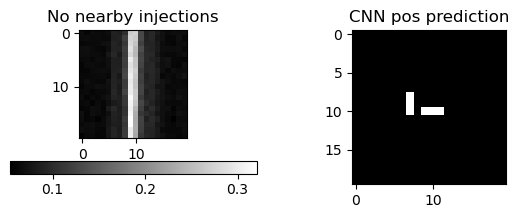

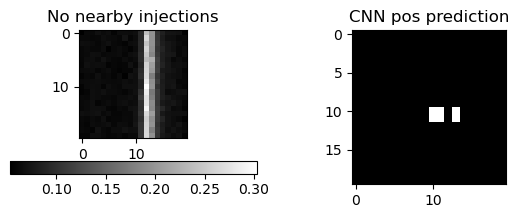

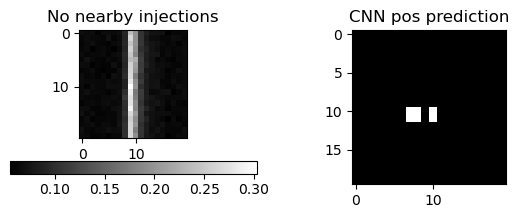

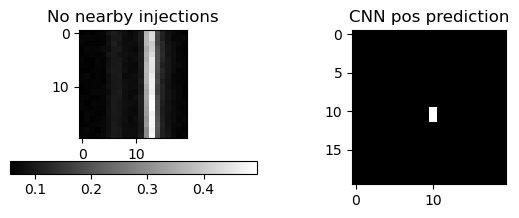

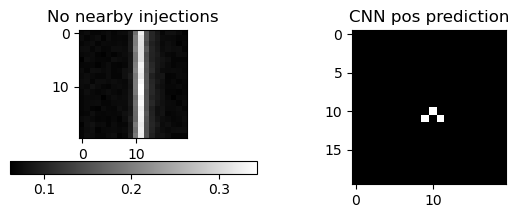

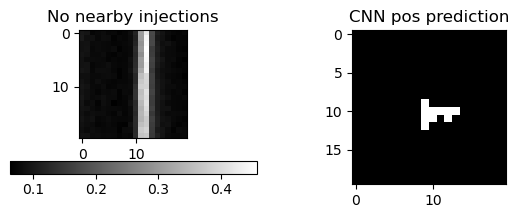

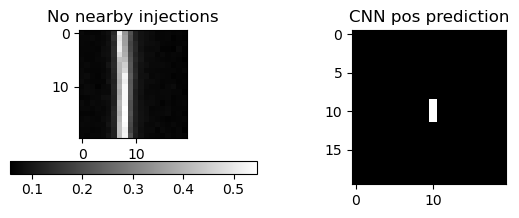

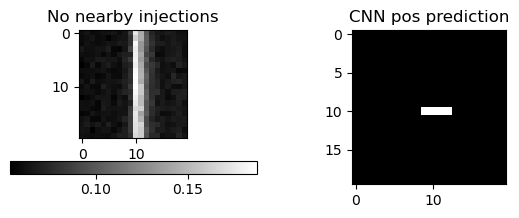

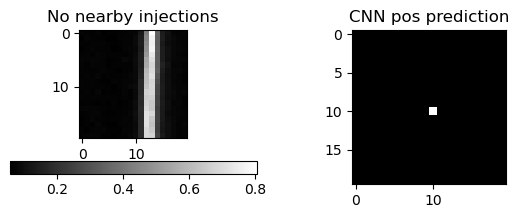

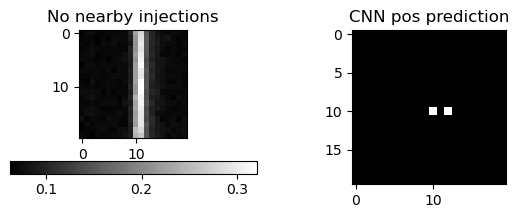

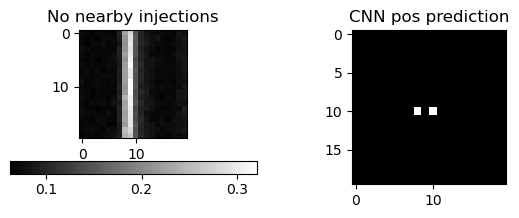

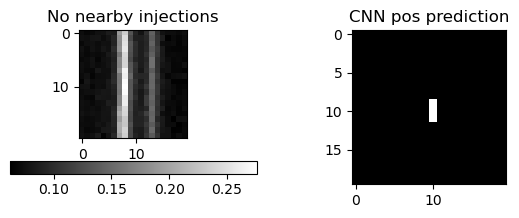

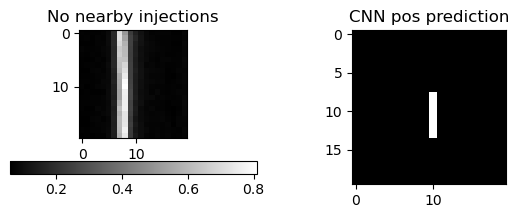

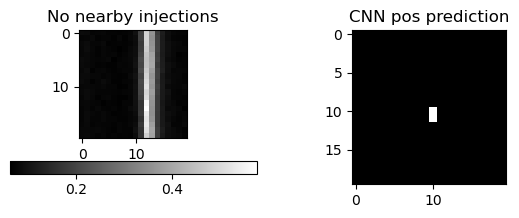

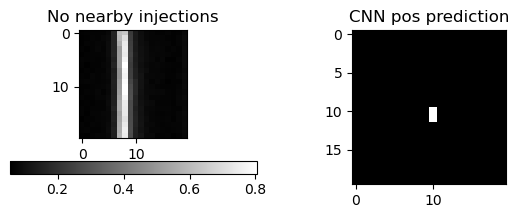

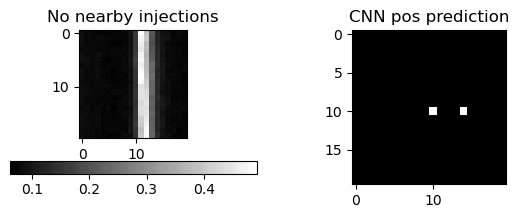

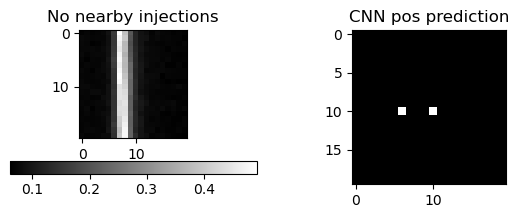

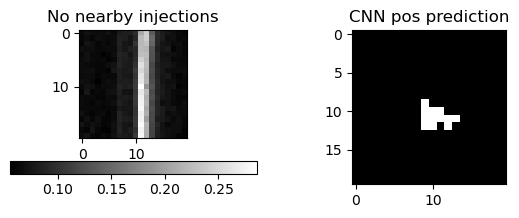

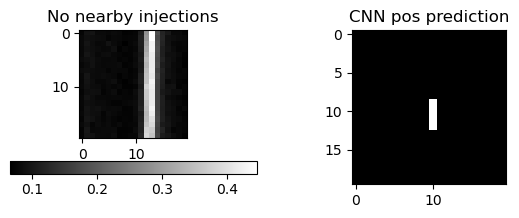

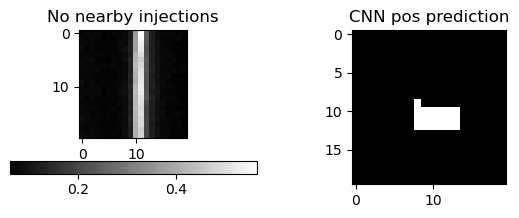

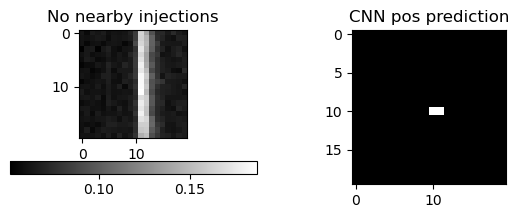

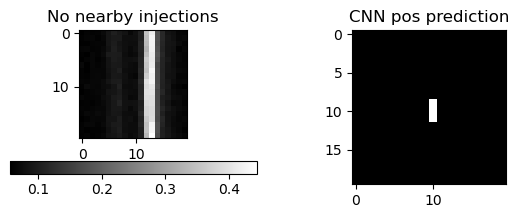

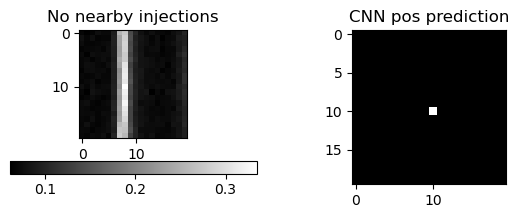

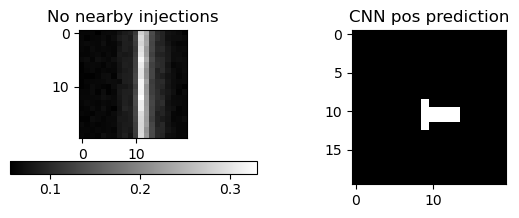

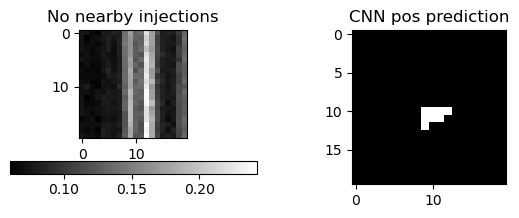

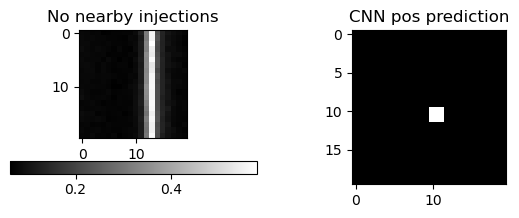

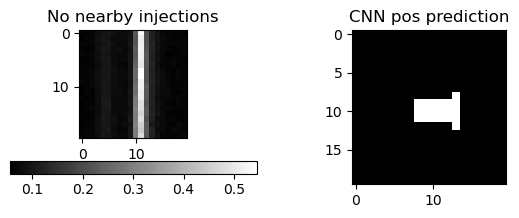

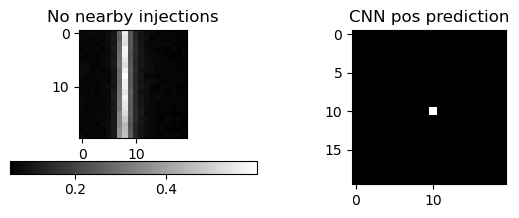

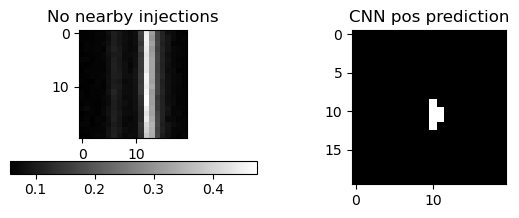

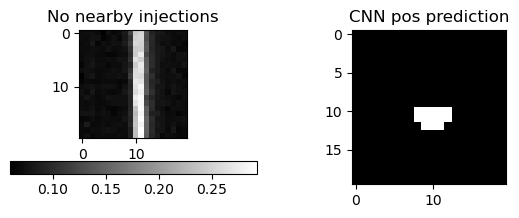

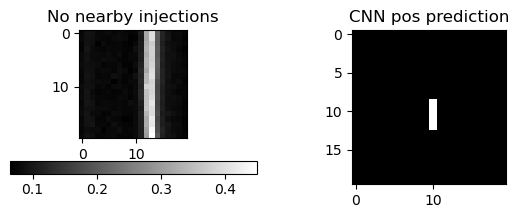

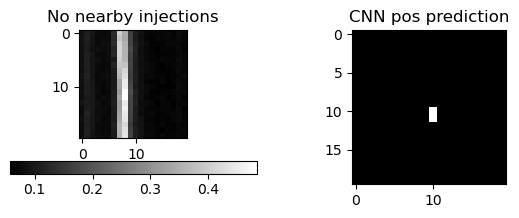

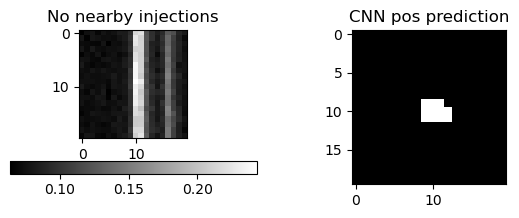

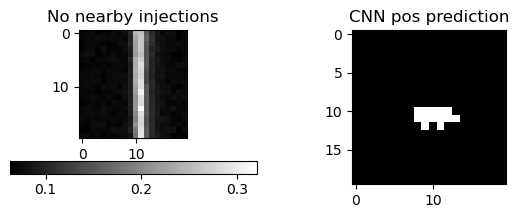

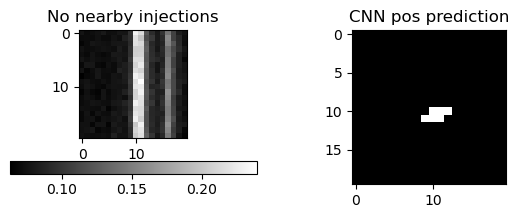

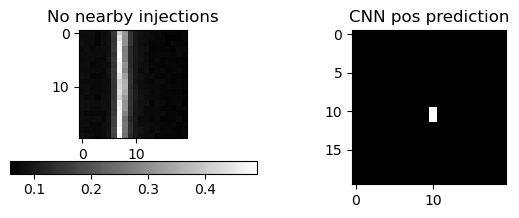

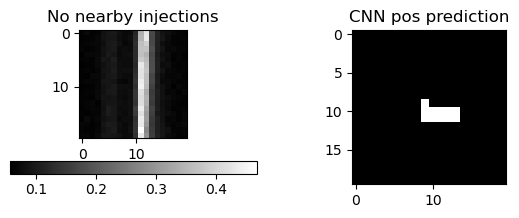

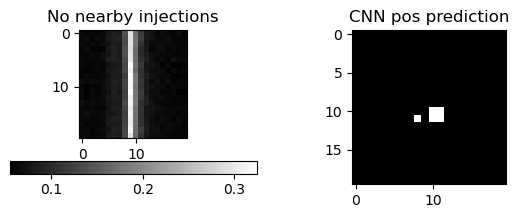

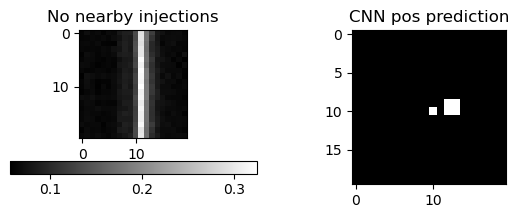

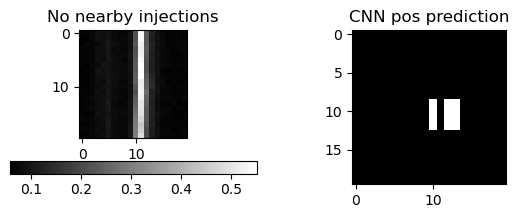

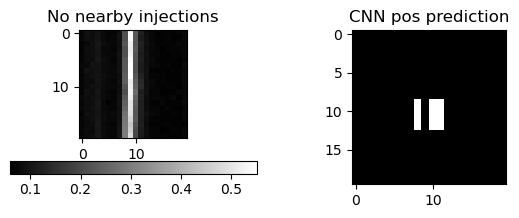

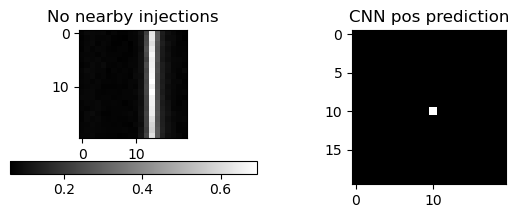

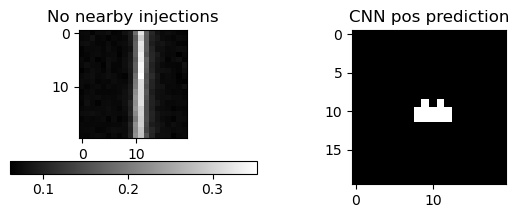

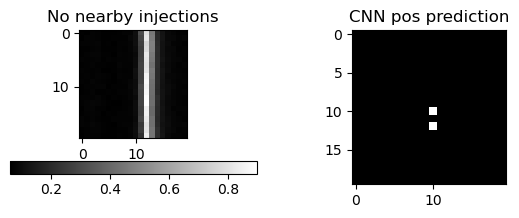

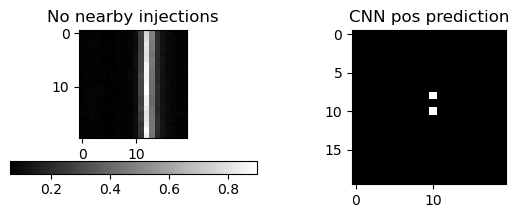

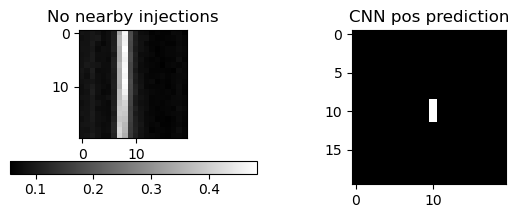

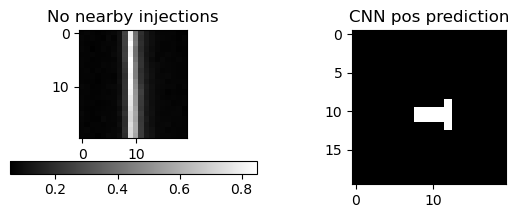

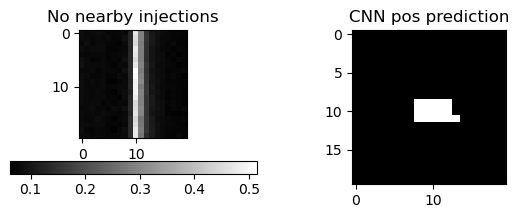

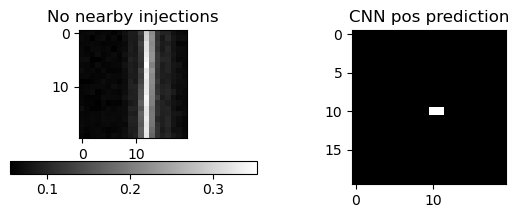

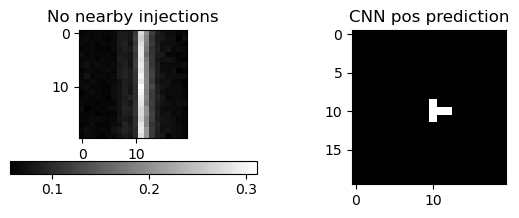

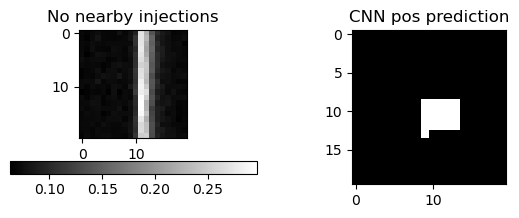

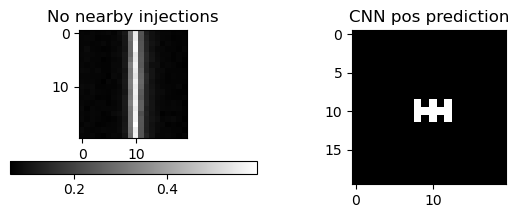

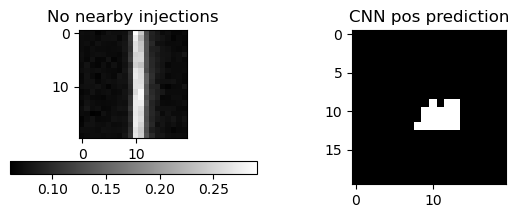

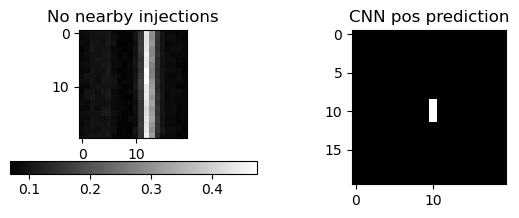

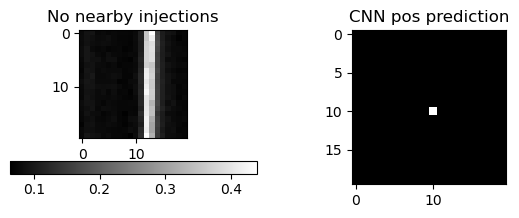

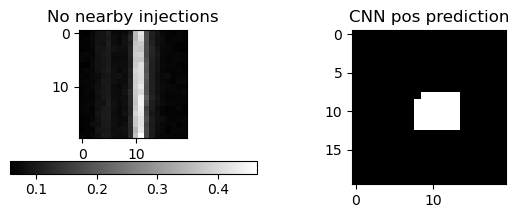

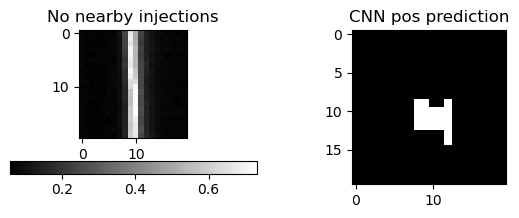

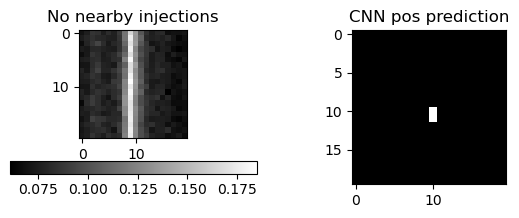

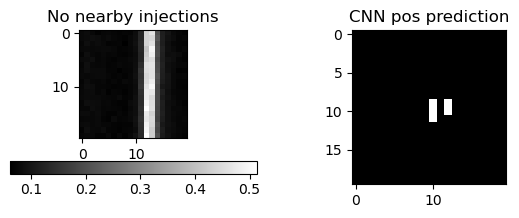

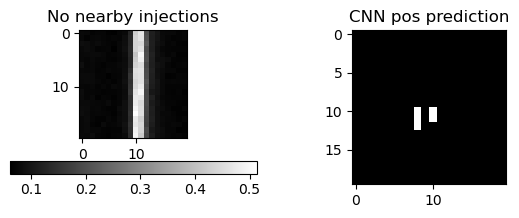

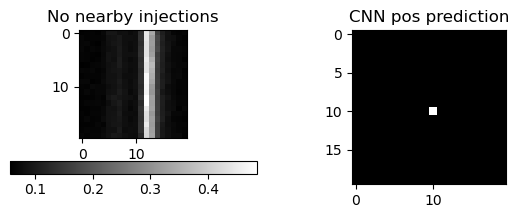

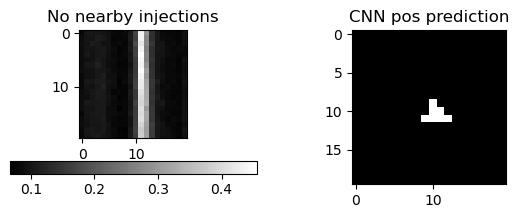

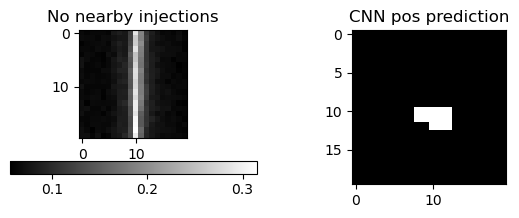

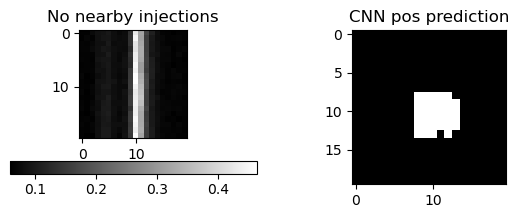

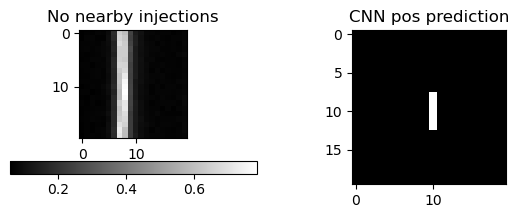

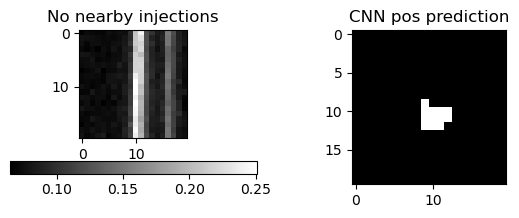

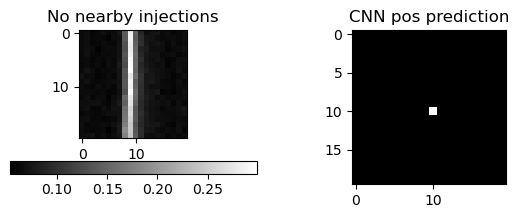

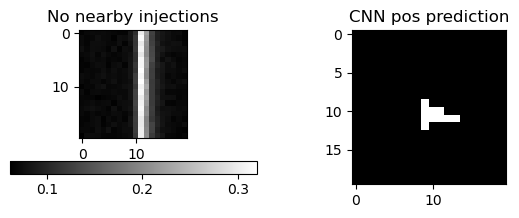

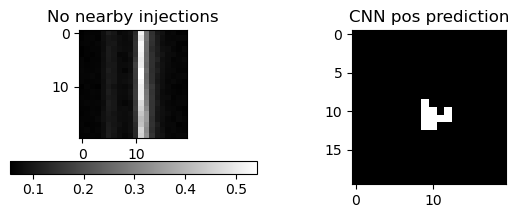

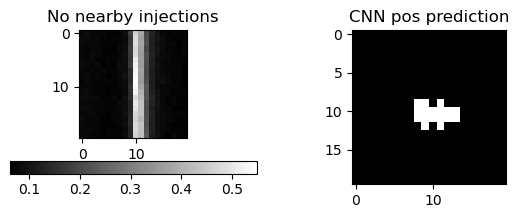

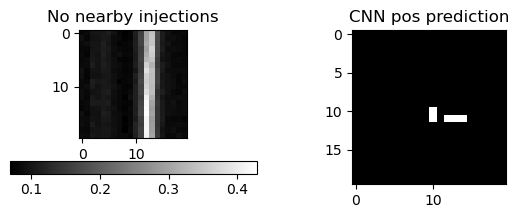

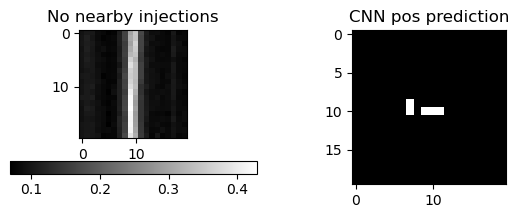

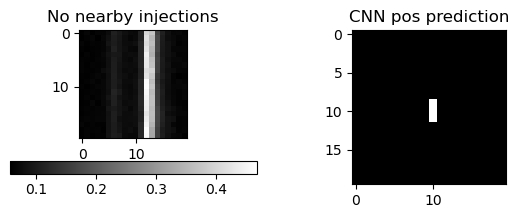

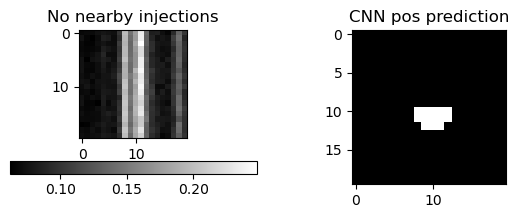

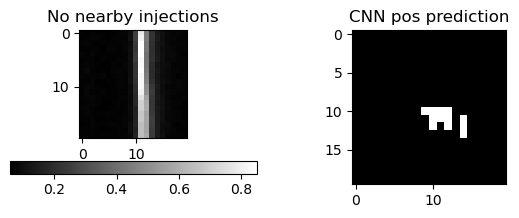

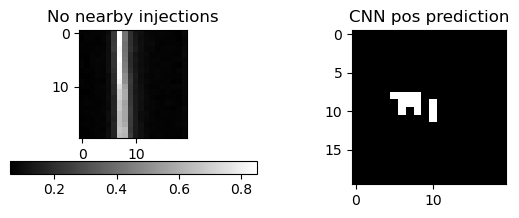

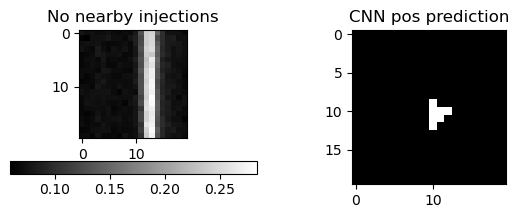

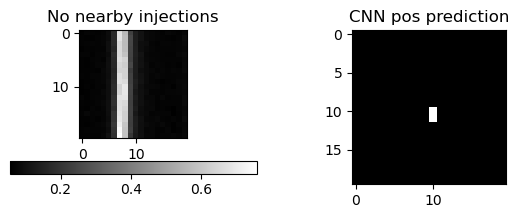

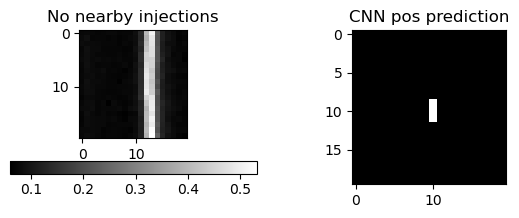

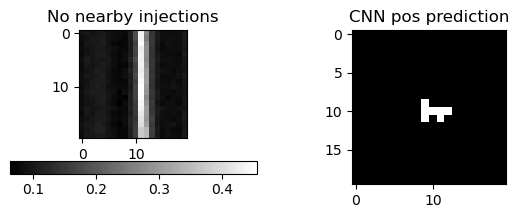

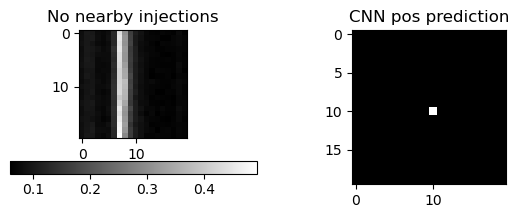

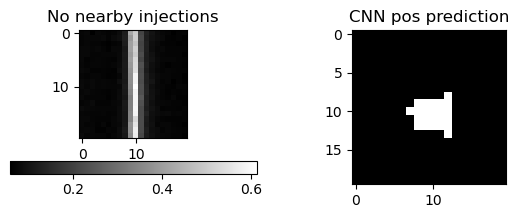

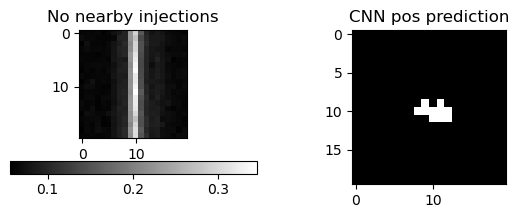

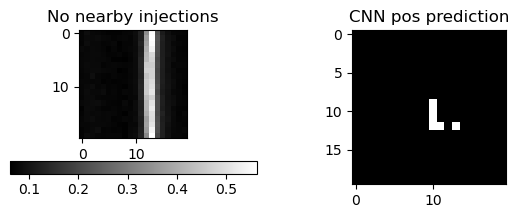

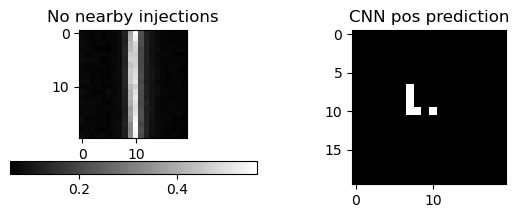

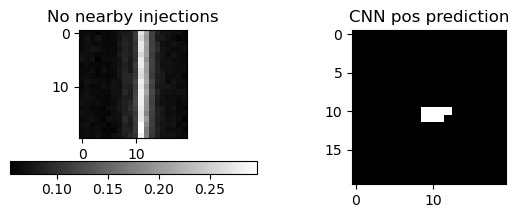

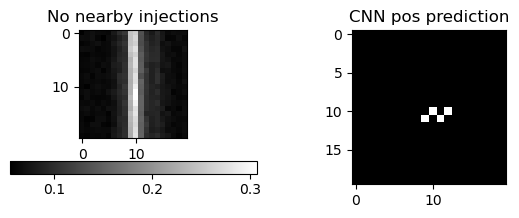

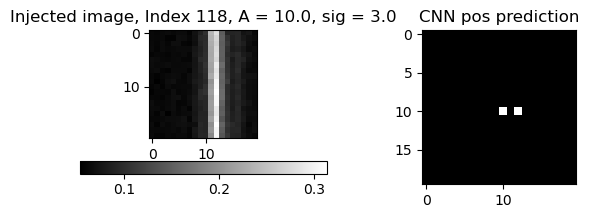

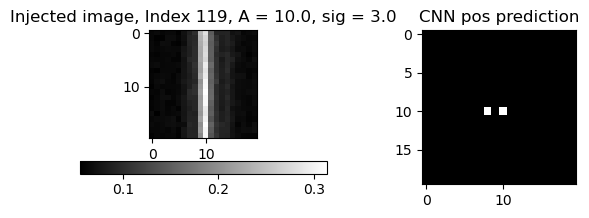

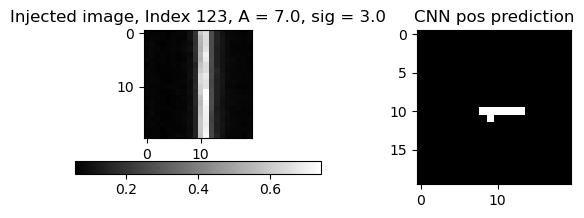

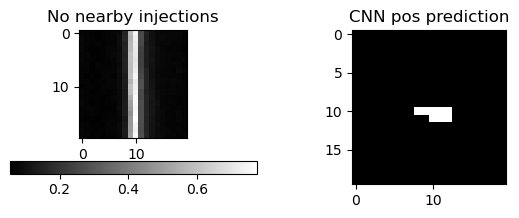

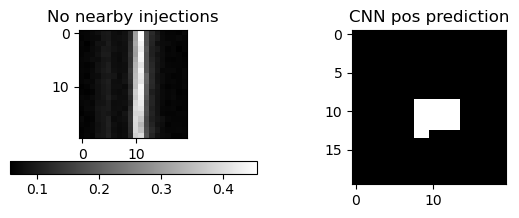

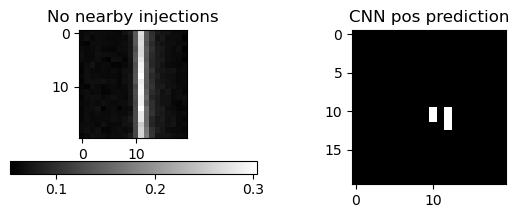

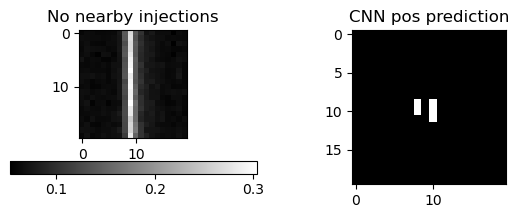

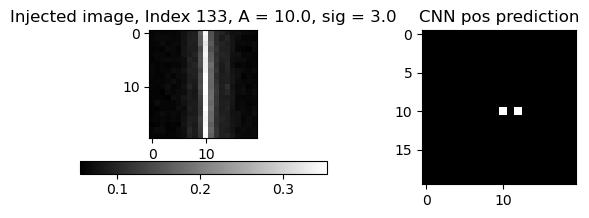

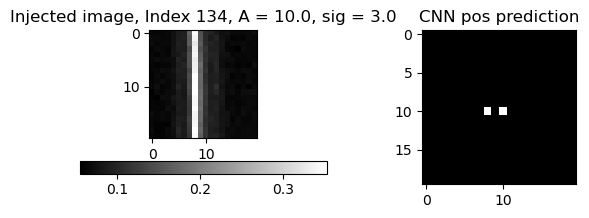

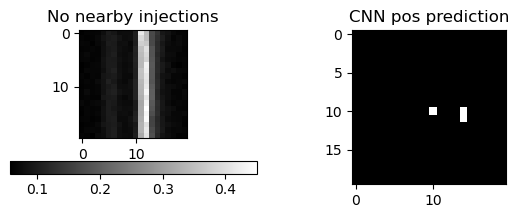

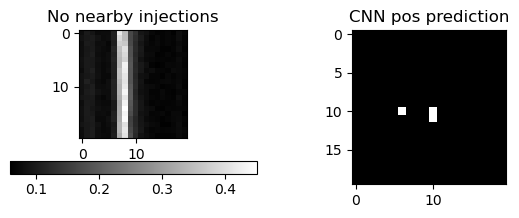

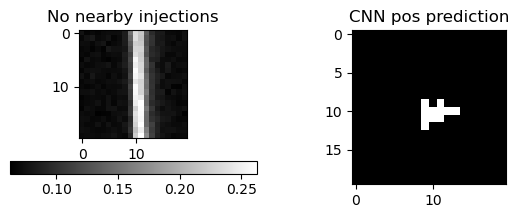

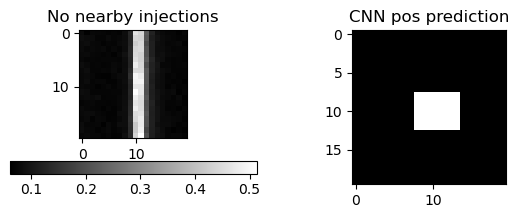

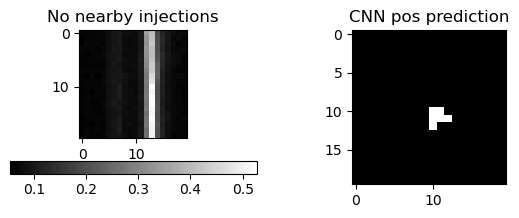

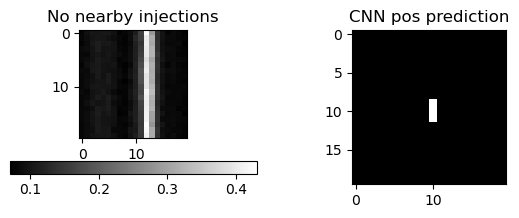

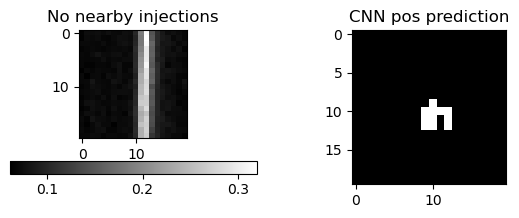

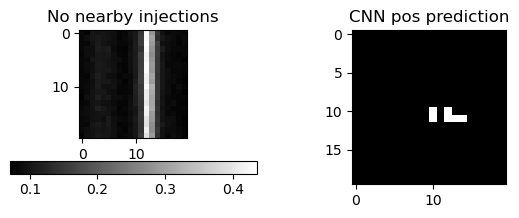

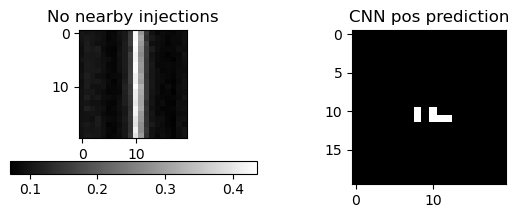

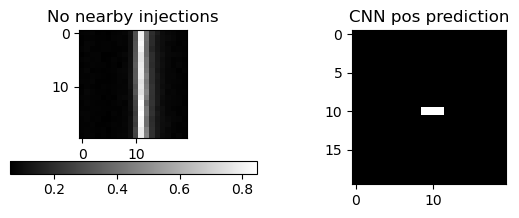

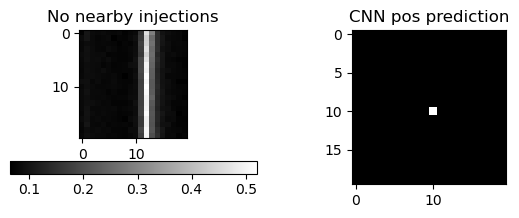

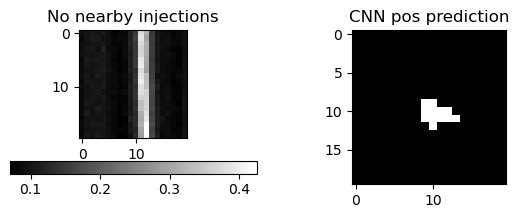

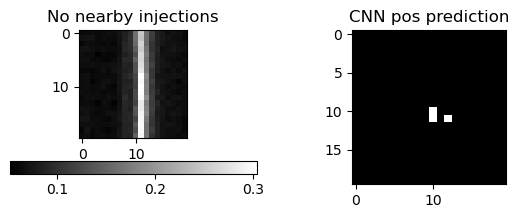

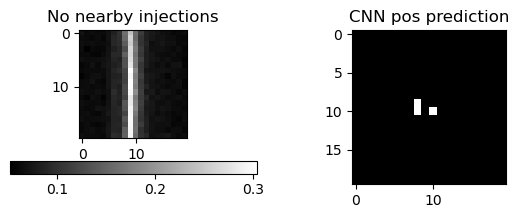

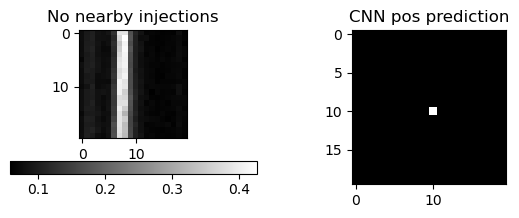

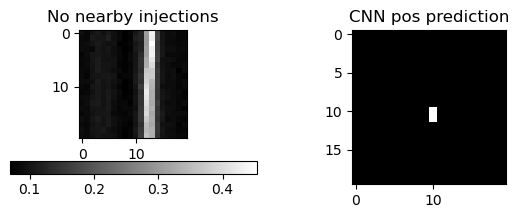

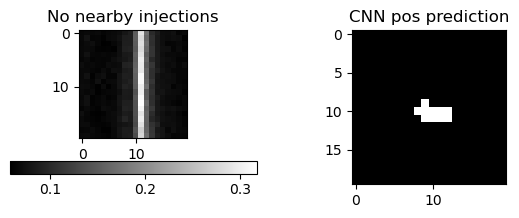

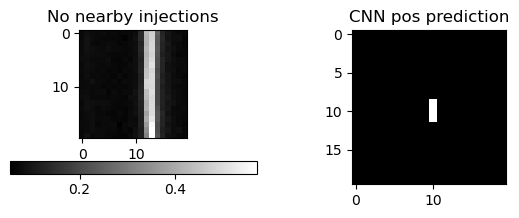

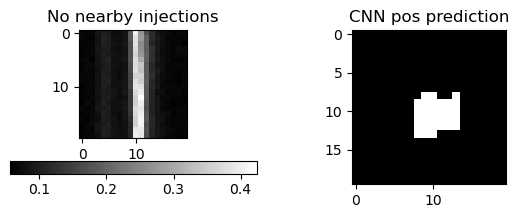

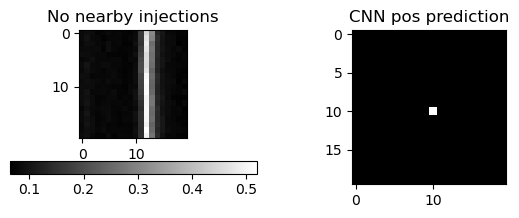

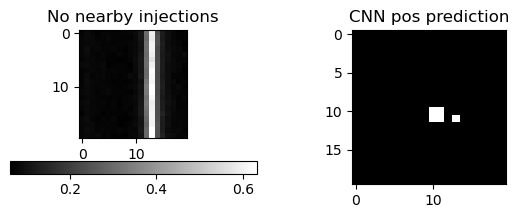

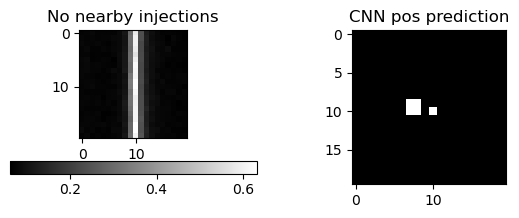

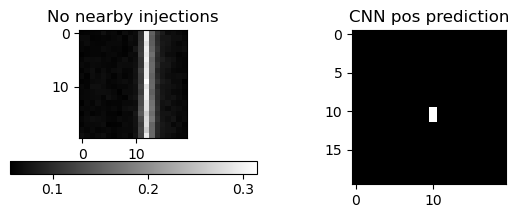

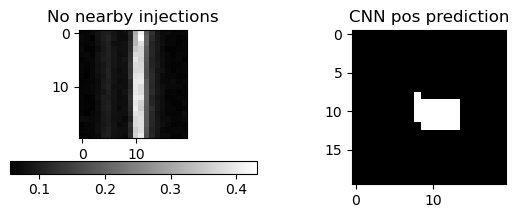

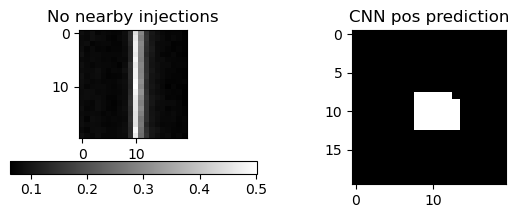

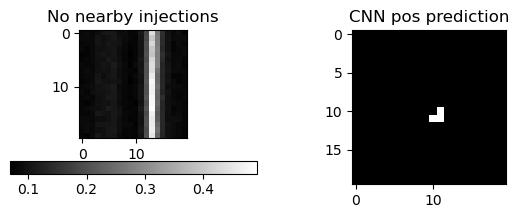

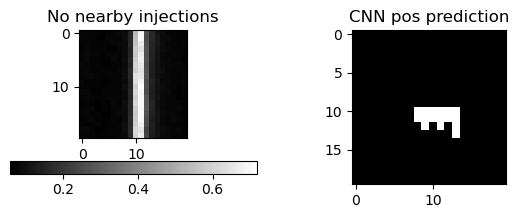

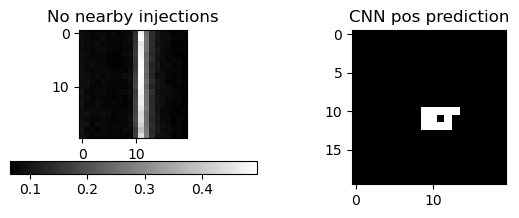

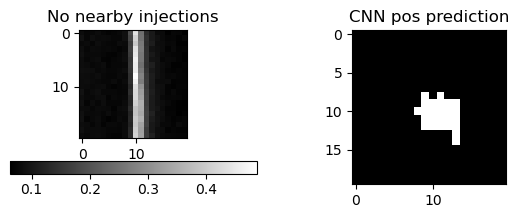

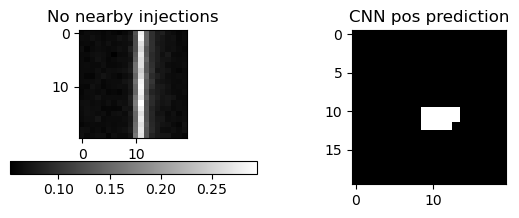

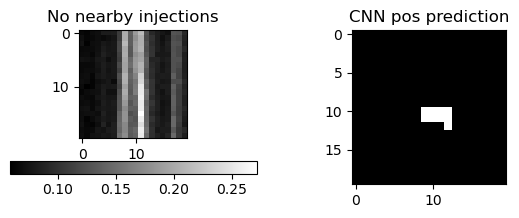

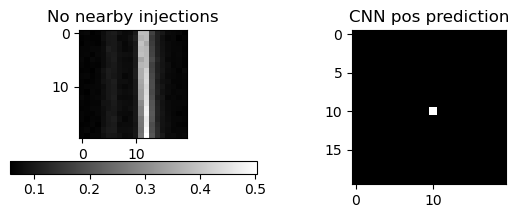

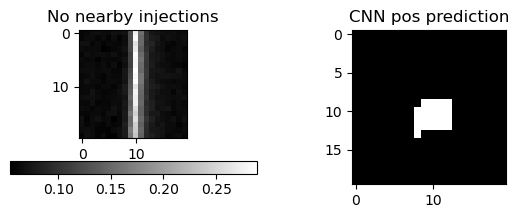

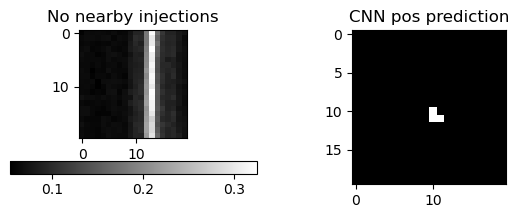

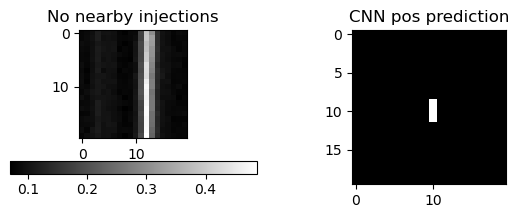

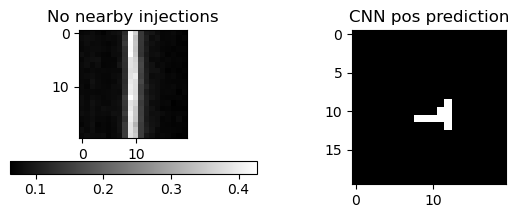

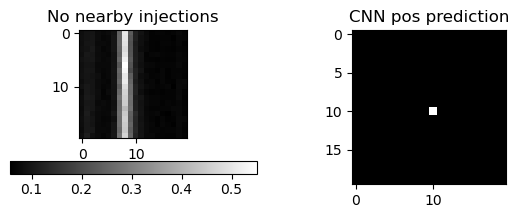

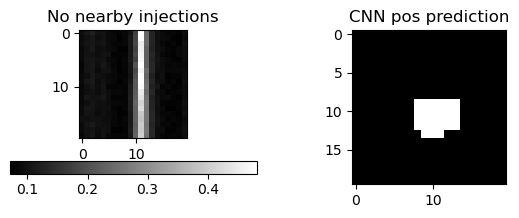

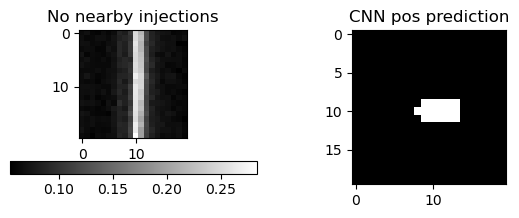

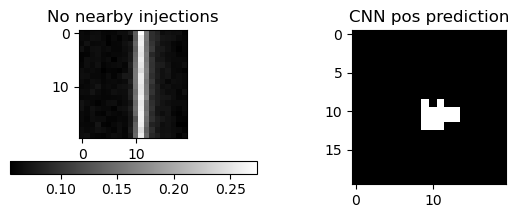

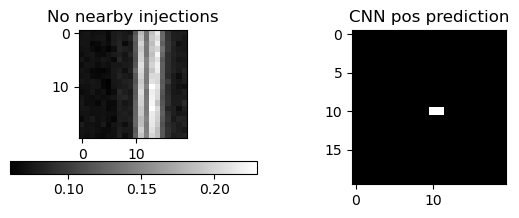

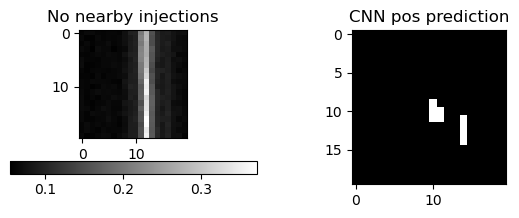

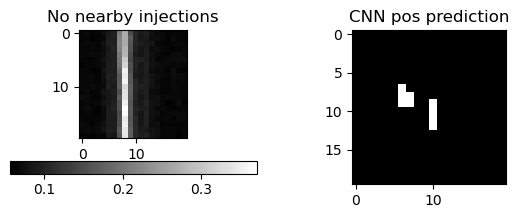

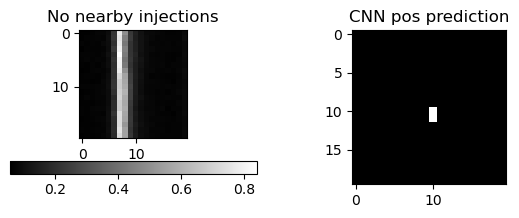

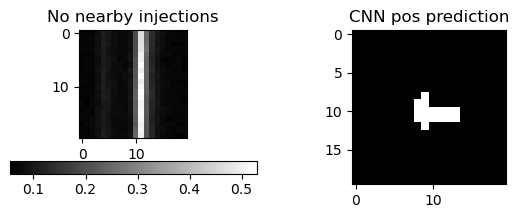

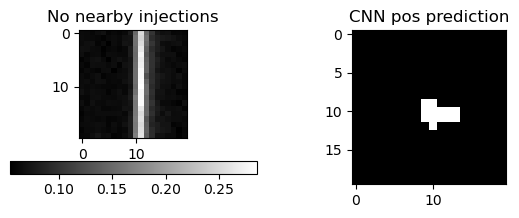

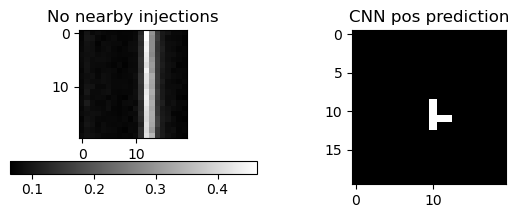

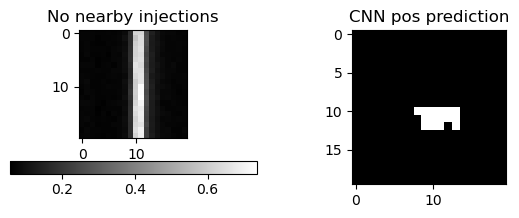

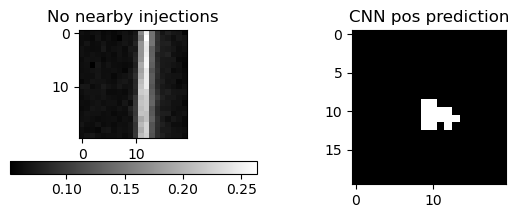

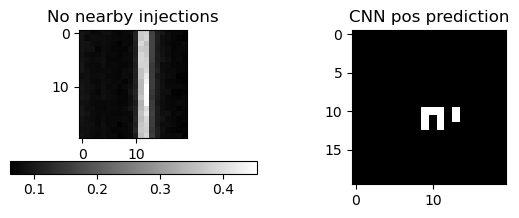

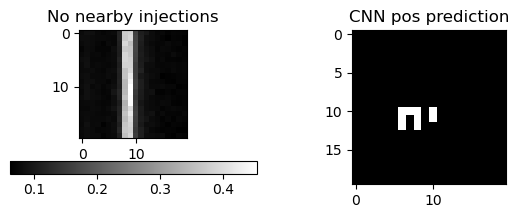

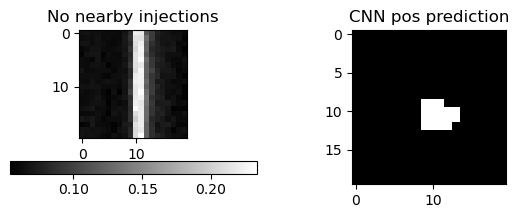

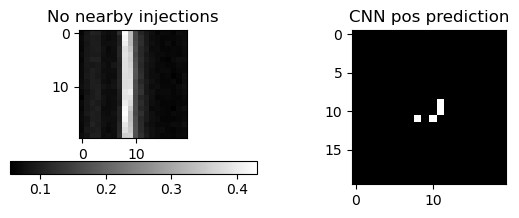

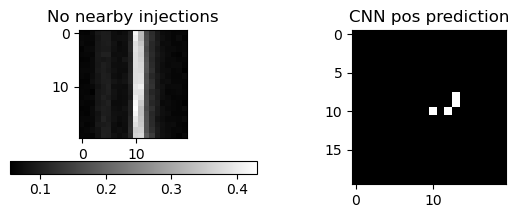

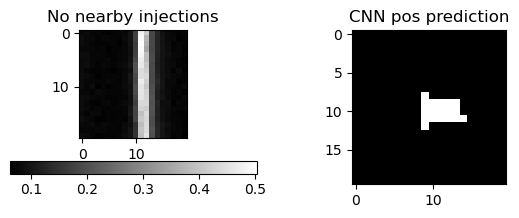

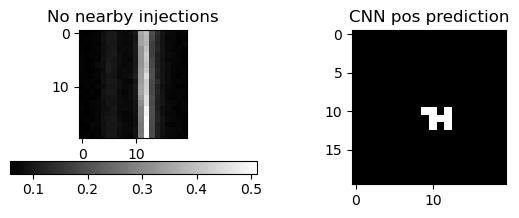

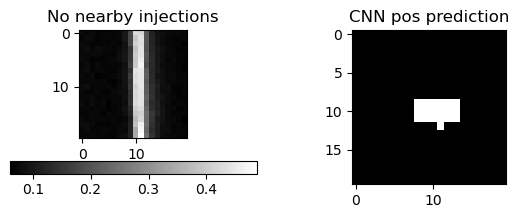

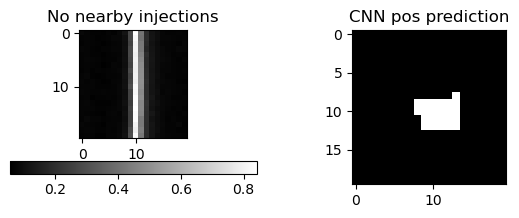

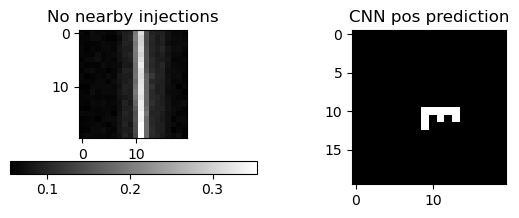

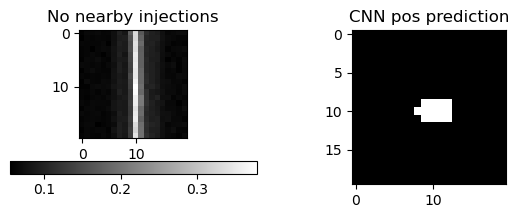

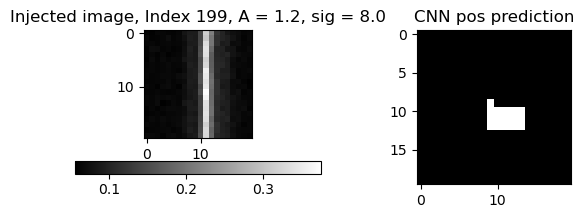

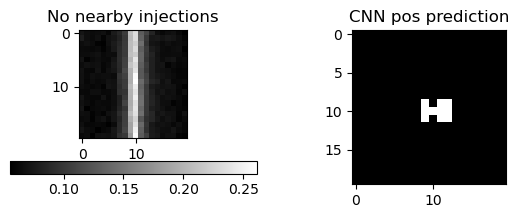

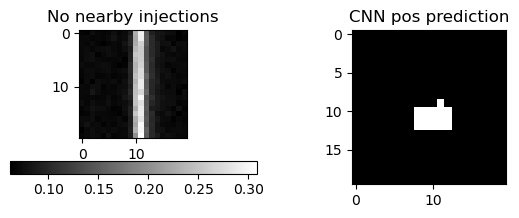

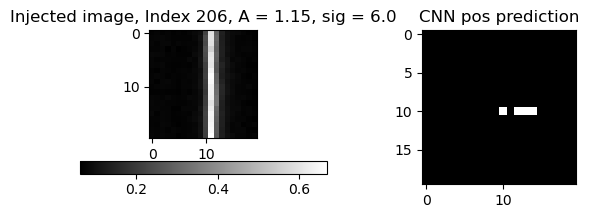

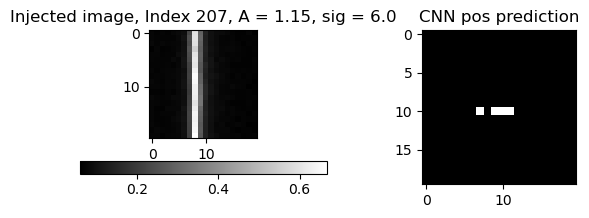

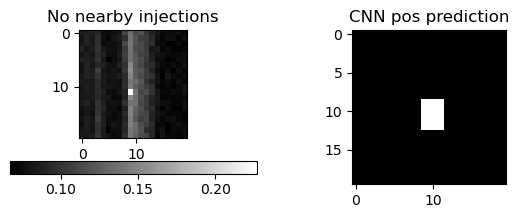

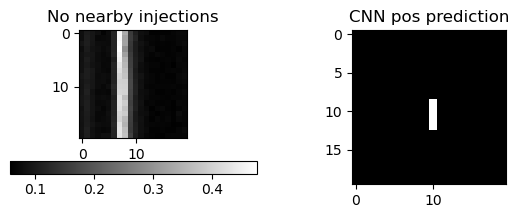

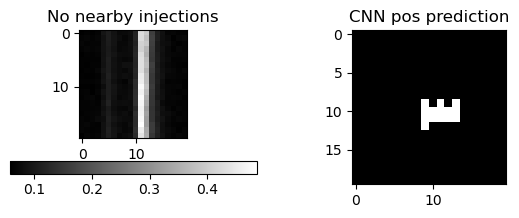

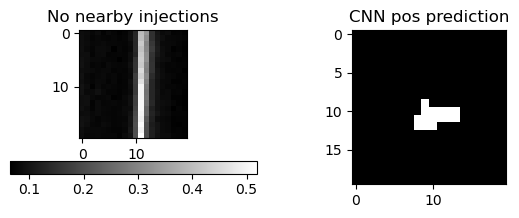

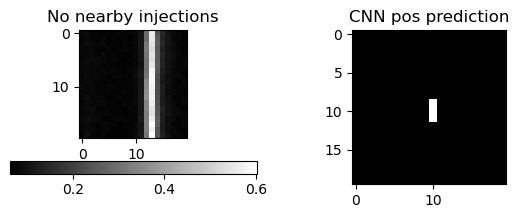

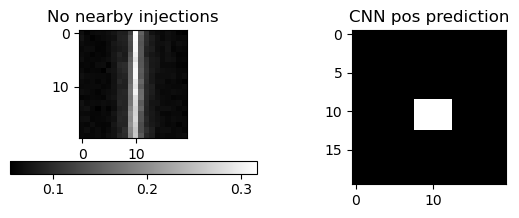

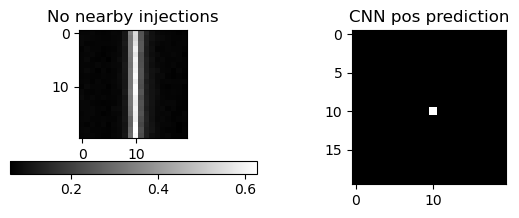

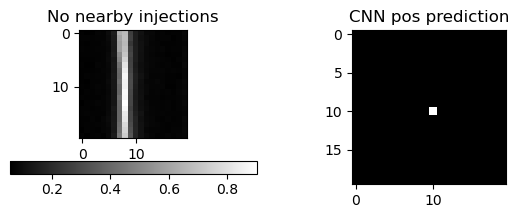

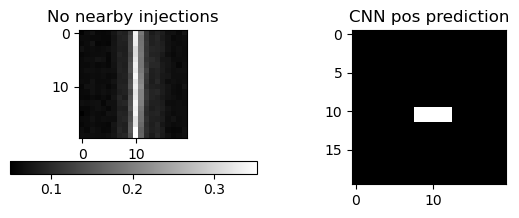

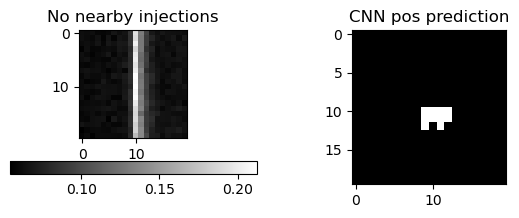

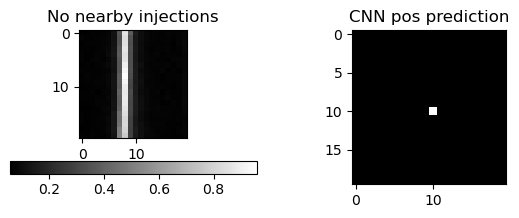

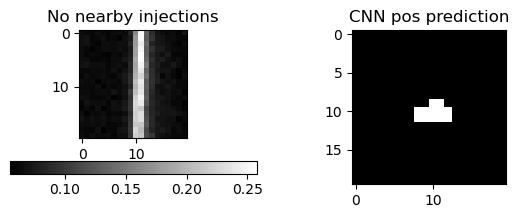

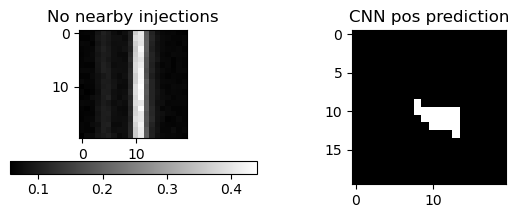

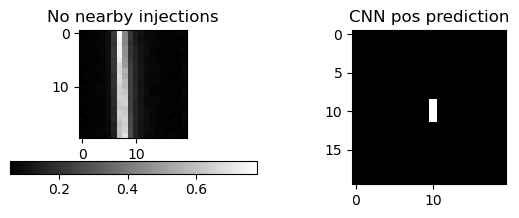

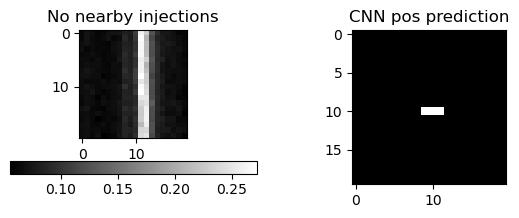

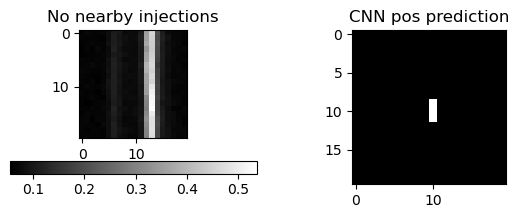

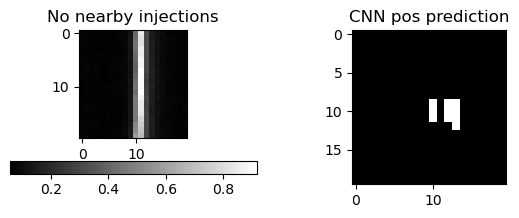

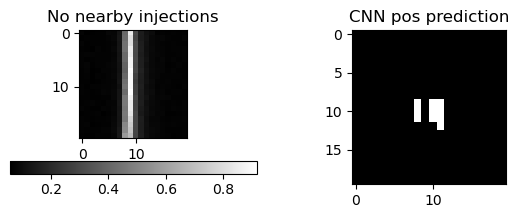

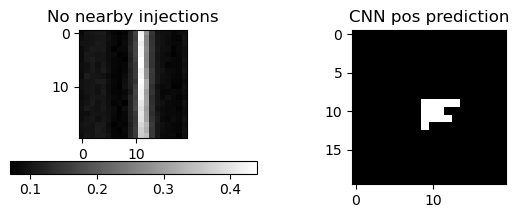

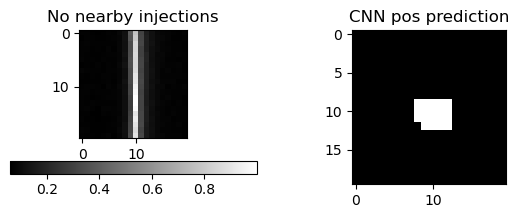

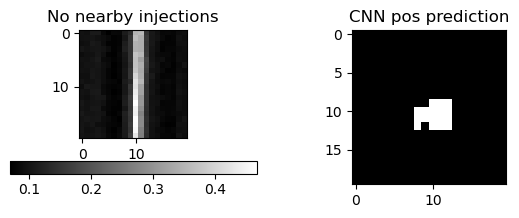

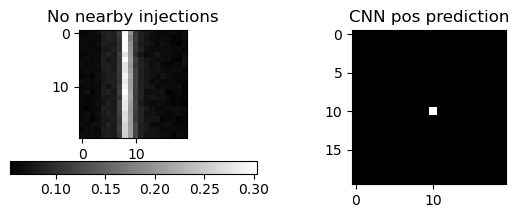

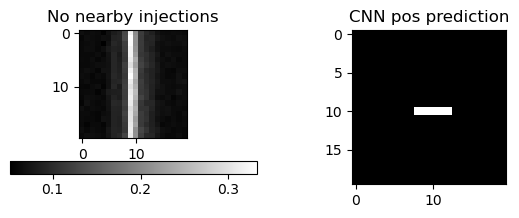

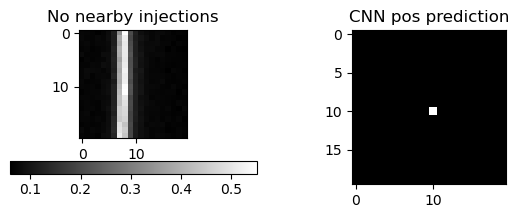

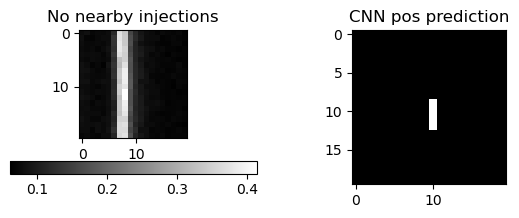

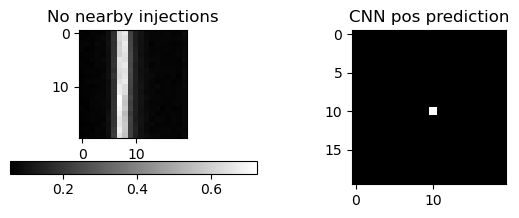

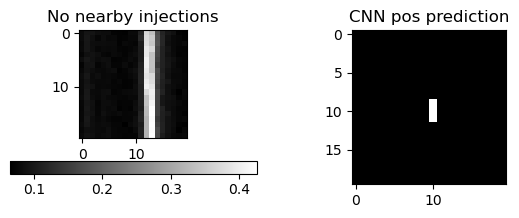

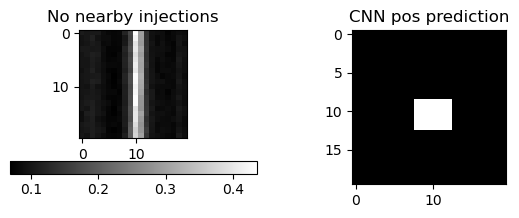

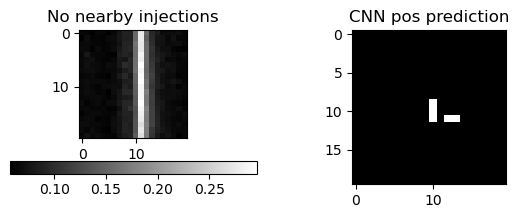

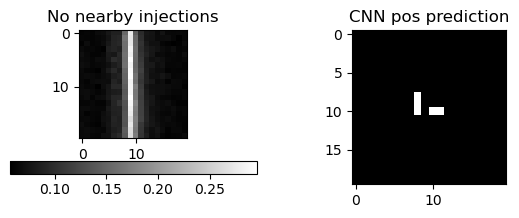

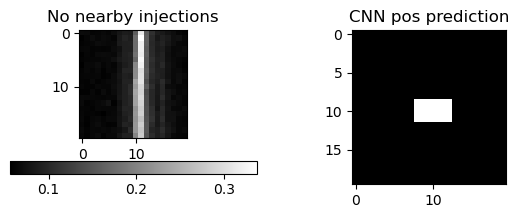

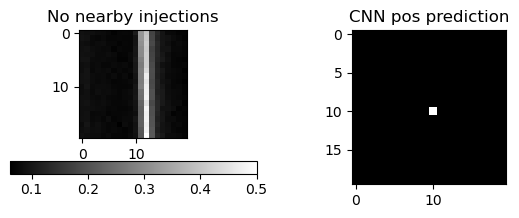

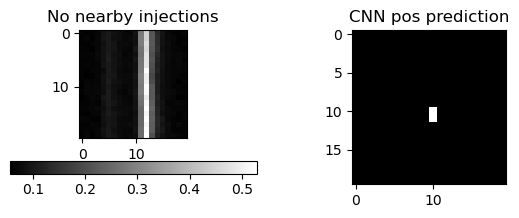

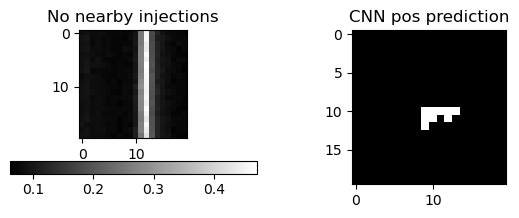

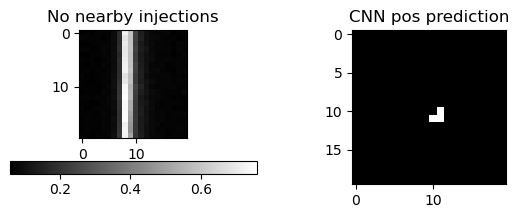

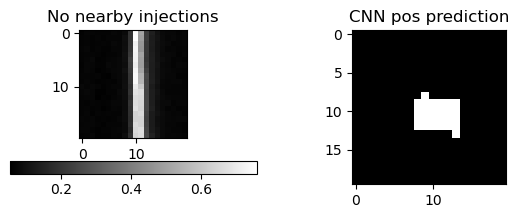

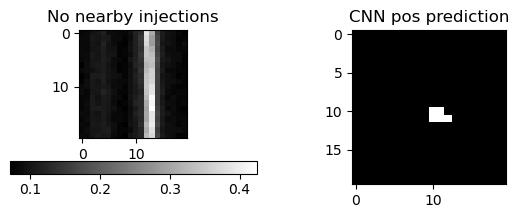

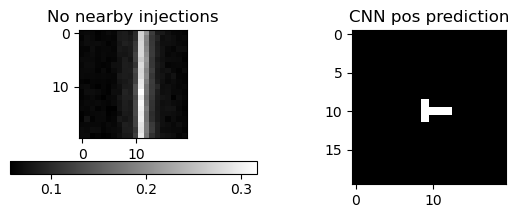

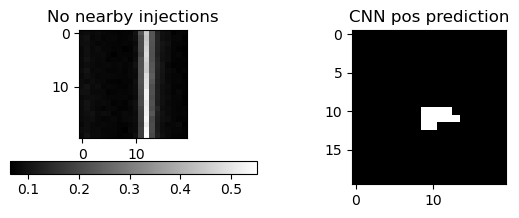

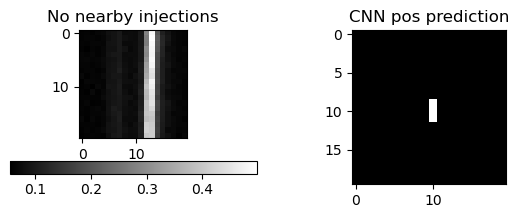

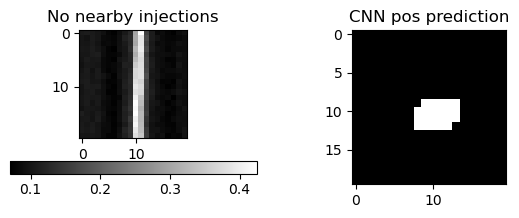

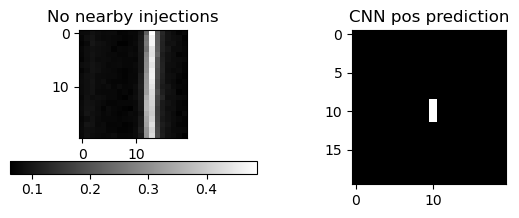

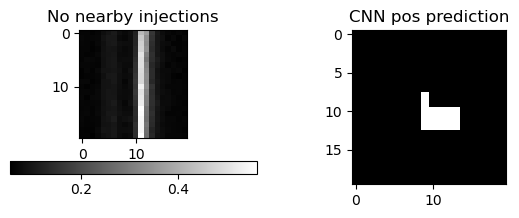

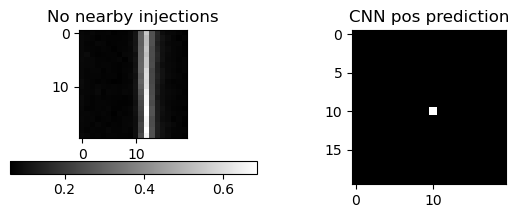

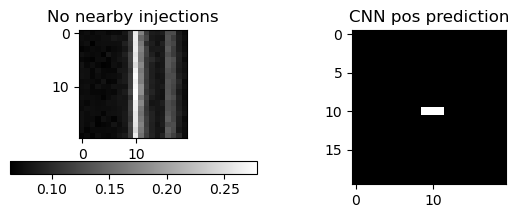

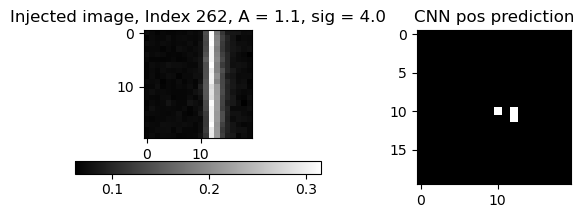

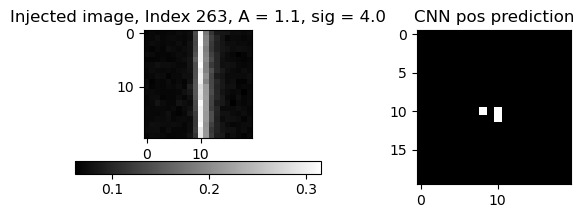

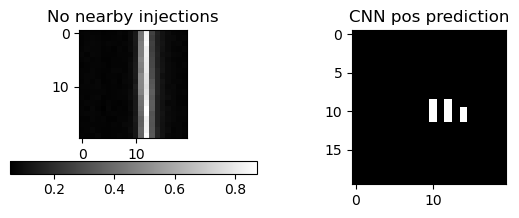

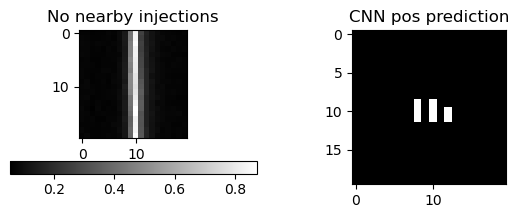

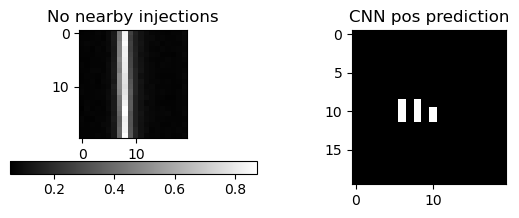

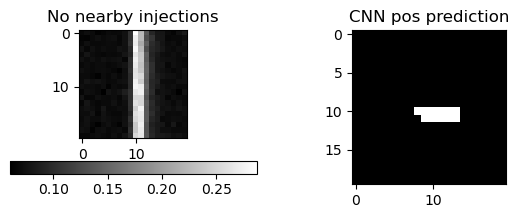

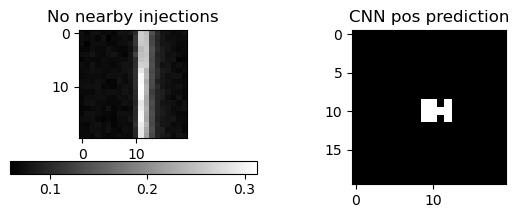

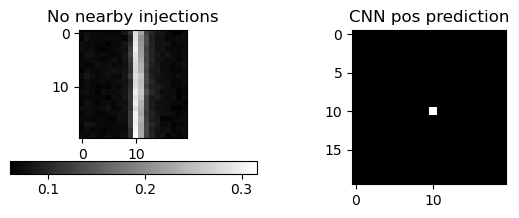

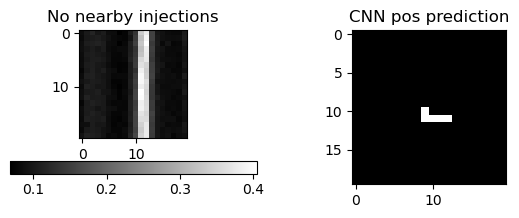

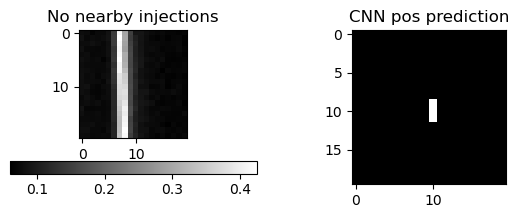

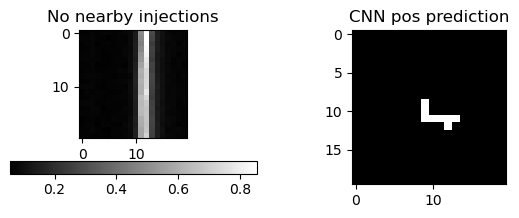

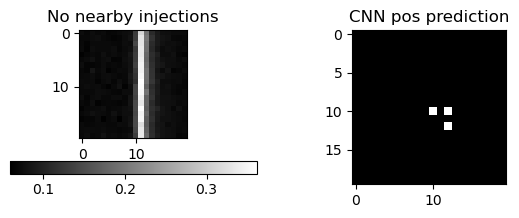

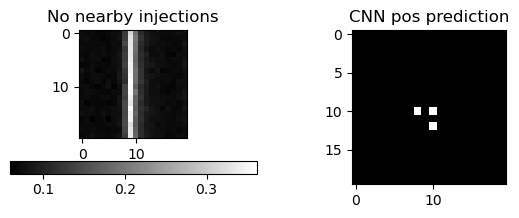

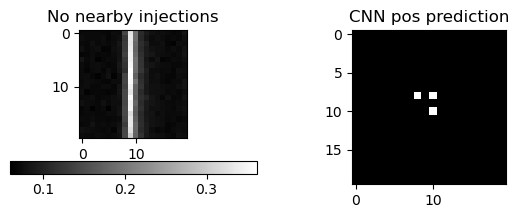

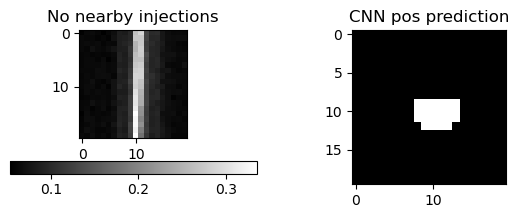

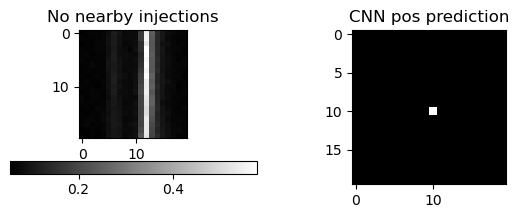

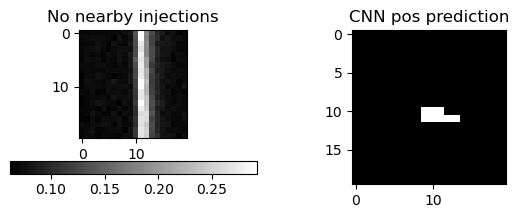

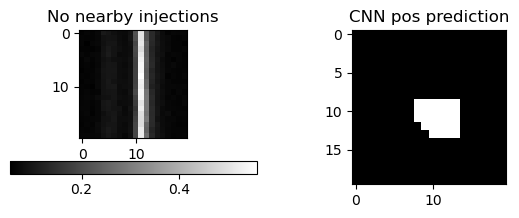

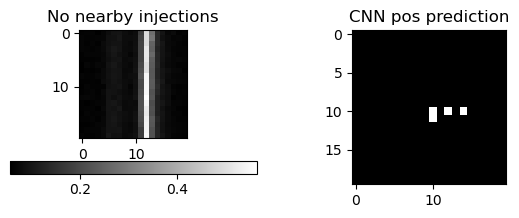

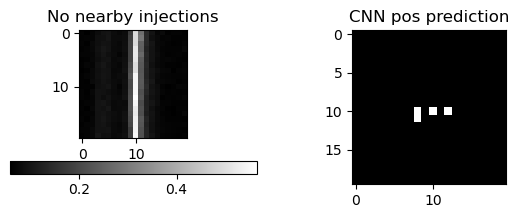

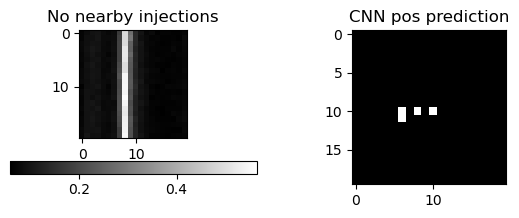

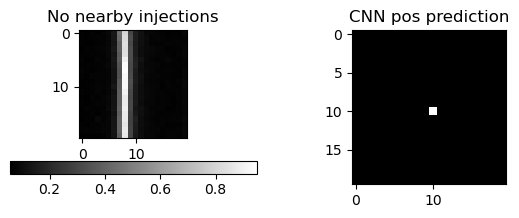

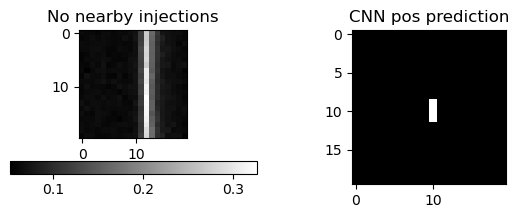

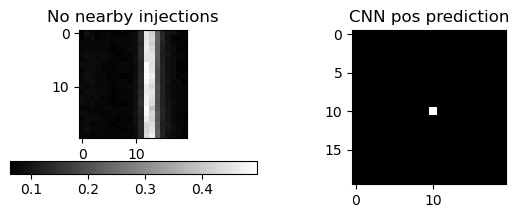

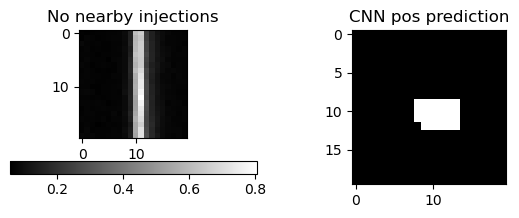

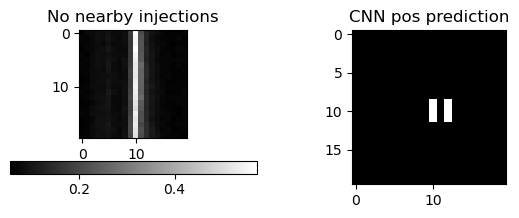

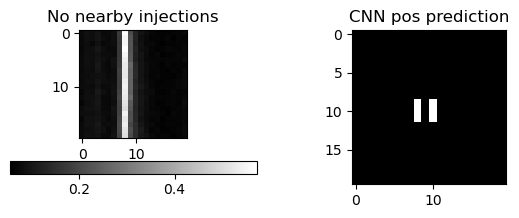

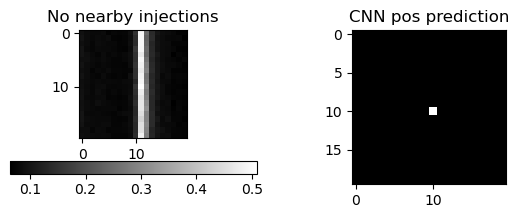

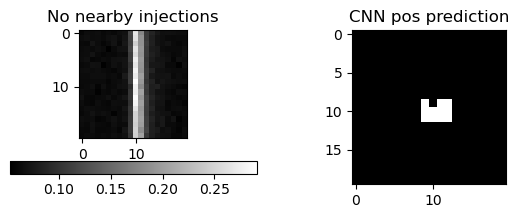

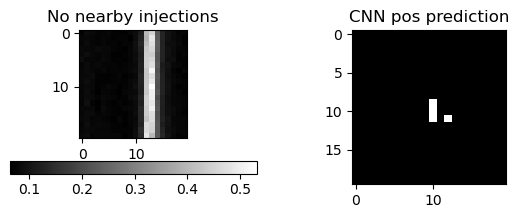

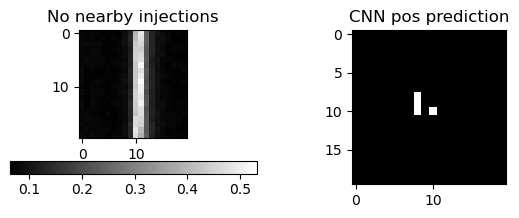

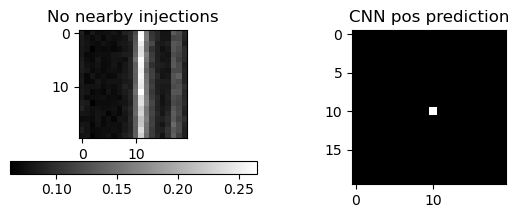

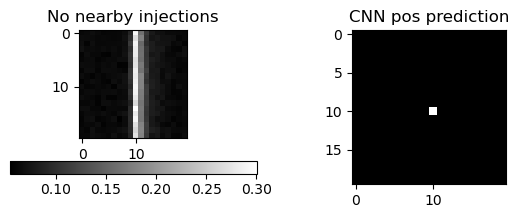

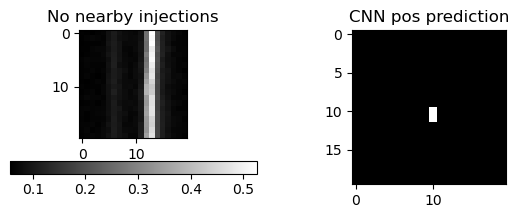

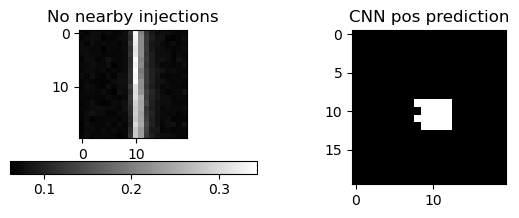

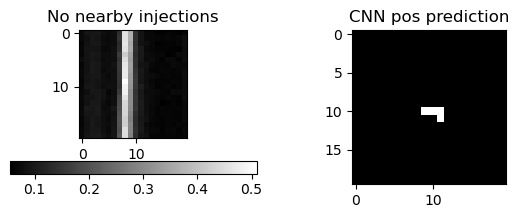

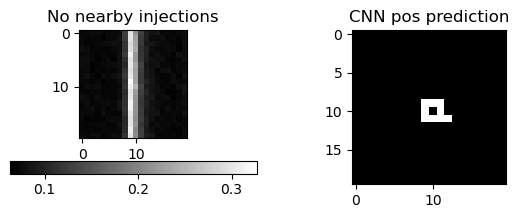

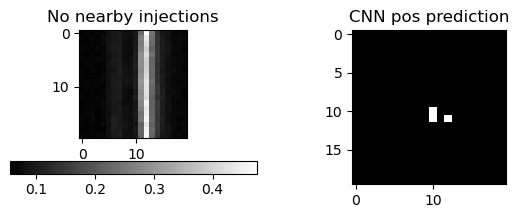

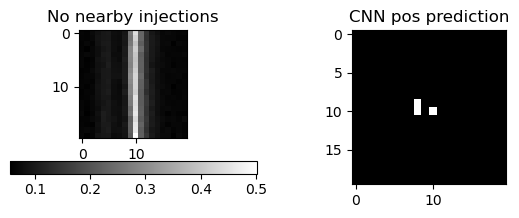

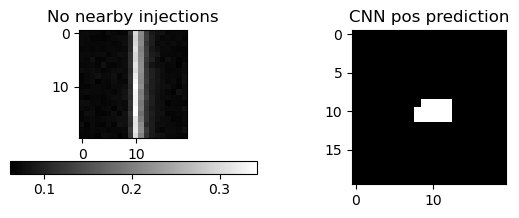

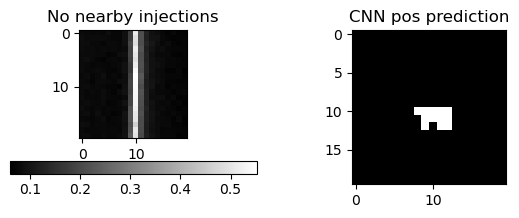

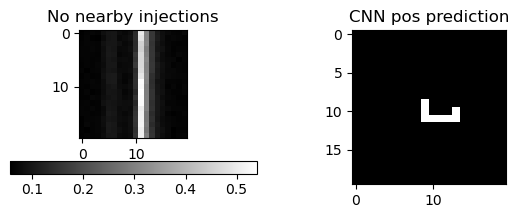

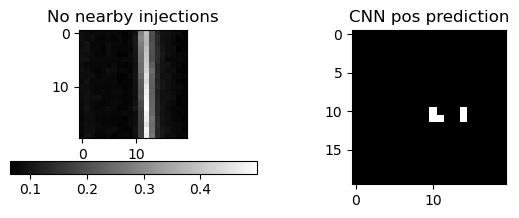

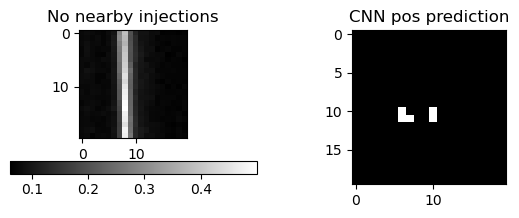

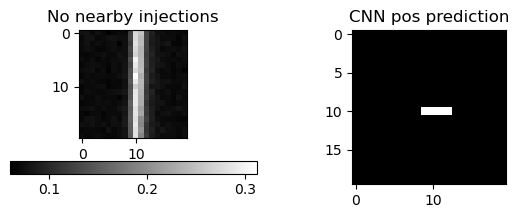

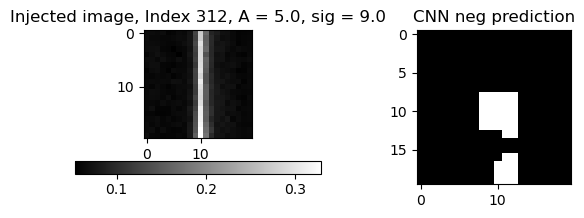

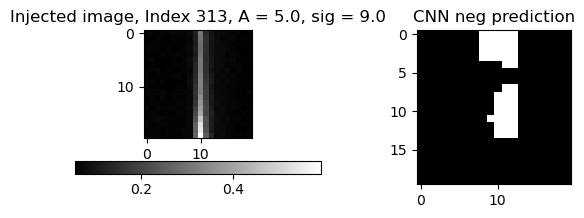

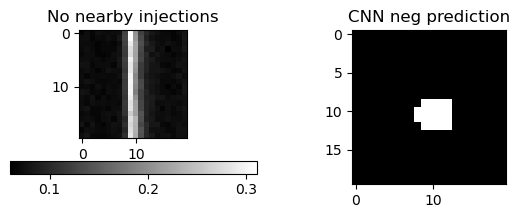

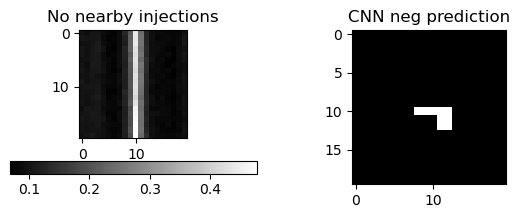

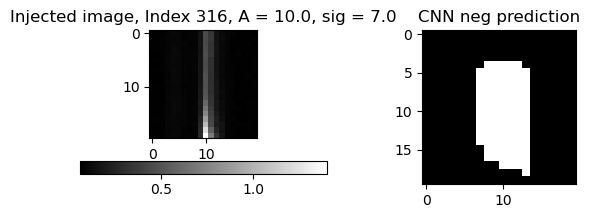

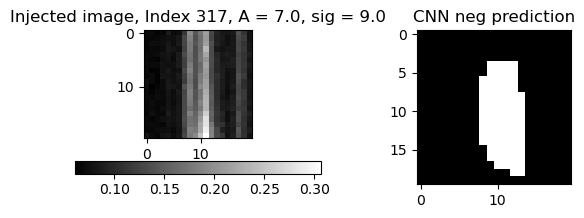

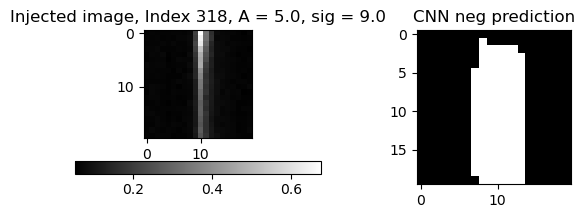

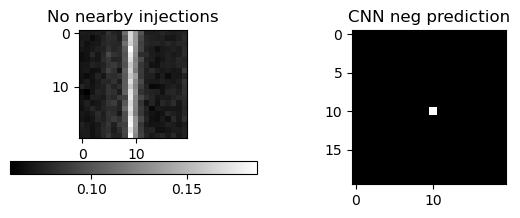

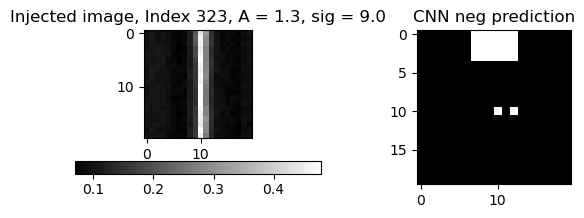

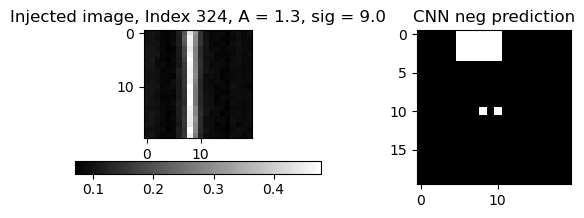

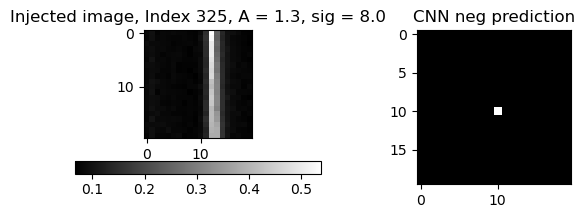

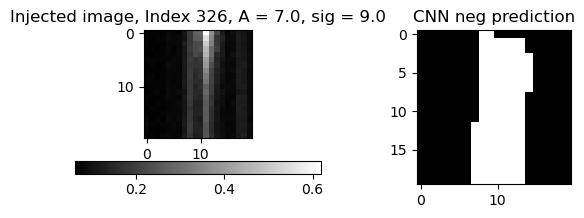

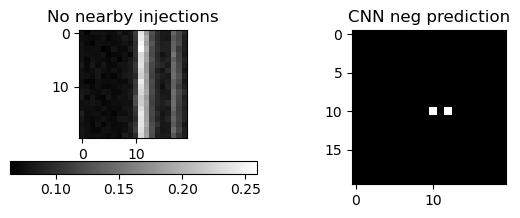

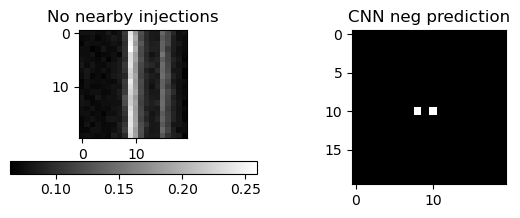

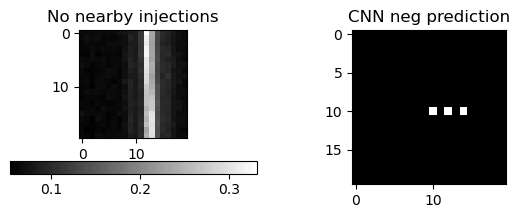

KeyboardInterrupt: 

<Figure size 700x200 with 0 Axes>

In [59]:
for index in df[df['dist_to_implant']>20].index:
    rff.inspect_stamp_and_map(df, index, posneg='pos', varthresh=.7,neweff="nosat_eff_data/", pdirec='predsarrays_average')

In [128]:
df.loc[0]

Unnamed: 0.1                                                  0
Unnamed: 0                                                    0
filename               ztf_20221020148032_000686_zg_c02_x_0001.
quad                                                          1
type                                                        pos
row_from_nn                                           38.714286
col_from_nn                                          240.071429
detection_size                                               42
closest_x                                                 250.0
closest_y                                                1761.0
Diff                                                  -0.071429
brightness_ranking                                            6
quadrant                                                      1
num_in_file_in_star                                        10.0
dup_indices                                                  []
is_smaller_dup                          

In [136]:
df.drop(columns=['Unnamed: 0.1', 'Unnamed: 0'])

,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,Diff,brightness_ranking,quadrant,num_in_file_in_star,dup_indices,is_smaller_dup,dist_to_implant,row_from_implant,col_from_implant,A_from_implant,sig_from_implant
0,ztf_20221020148032_000686_zg_c02_x_0001.,1,pos,38.714286,240.071429,42,250.0,1761.0,-0.071429,6,1,10.0,[],0.0,0.294508,49.0,250.0,1.50,4.0
1,ztf_20221020148032_000686_zg_c02_x_0001.,1,pos,42.061728,476.086420,81,487.0,435.0,0.913580,1,1,12.0,[],0.0,0.942243,53.0,486.0,10.00,5.0
2,ztf_20221020148032_000686_zg_c02_x_0001.,1,pos,46.745455,1430.381818,55,1441.0,1579.0,0.618182,2,1,6.0,[],0.0,1.398583,58.0,1441.0,1.20,5.0
3,ztf_20221020148032_000686_zg_c02_x_0001.,1,pos,71.750000,2256.916667,24,2266.0,1067.0,-0.916667,9,1,4.0,[],0.0,0.950146,82.0,2266.0,5.00,4.0
4,ztf_20221020148032_000686_zg_c02_x_0001.,1,pos,85.644068,2954.305085,59,2964.0,425.0,-0.305085,3,1,5.0,[],0.0,1.389831,97.0,2964.0,1.50,7.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1263,ztf_20221020294271_000449_zr_c04_x_0004.,3,neg,2376.250000,2028.350000,20,2038.0,1087.0,-0.350000,0,3,22.0,[],0.0,11.755212,2398.0,2038.0,2.00,5.0
1264,ztf_20221020294271_000449_zr_c04_x_0004.,3,neg,2401.161290,2028.387097,62,2038.0,1087.0,-0.387097,0,3,22.0,[],0.0,13.166982,2398.0,2038.0,2.00,5.0
1265,ztf_20221020294271_000449_zr_c04_x_0004.,3,neg,2455.254237,2557.593220,59,2568.0,2214.0,0.406780,7,3,7.0,[],0.0,13.260478,2452.0,2568.0,2.00,5.0
1266,ztf_20221020294271_000449_zr_c04_x_0004.,3,neg,2513.800000,1150.200000,5,1161.0,296.0,0.800000,2,3,8.0,[],0.0,71.804457,2452.0,1161.0,1.15,6.0


In [ ]:
#okay so now we want a 'general transient' detections dataframe
#right now i have my biggest df loaded as an example maybe ill geta smaller one 

In [188]:
df.iloc[0].copy()

Unnamed: 0.1                                                  0
Unnamed: 0                                                    0
filename               ztf_20221020148032_000686_zg_c02_x_0001.
quad                                                          1
type                                                        pos
row_from_nn                                           38.714286
col_from_nn                                          240.071429
detection_size                                               42
closest_x                                                 250.0
closest_y                                                1761.0
Diff                                                  -0.071429
brightness_ranking                                            6
quadrant                                                      1
num_in_file_in_star                                        10.0
dup_indices                                                  []
is_smaller_dup                          

In [324]:
def make_transient_detections_df(olddf, threshold=30):
    '''30 performs the best for thr=.99 
    lower than 30 decreases precision'''
    df = olddf.copy() #just to make sure i dont accidentally modify the old one in place
    newdf = pd.DataFrame()
    for filename, filenamegroup in df.groupby('filename'):  
        for quad, quadgroup in filenamegroup.groupby('quad'):
            for closest_x, closest_xgroup in quadgroup.groupby('closest_x'):
                ignore_in_this_group = []
                for i in closest_xgroup.index:
                    closest_idx = []
                    original_col = closest_xgroup.loc[i,'col_from_nn']
                    original_row = closest_xgroup.loc[i,'row_from_nn']
                    for j in closest_xgroup.index:
                        if j not in ignore_in_this_group:
                            if (np.abs(closest_xgroup.loc[j,'col_from_nn']-original_col)<5)*(np.abs(closest_xgroup.loc[j,'row_from_nn']-original_row)<threshold)*(j not in ignore_in_this_group):
                                if (closest_xgroup.loc[j,'dist_to_implant']>20) or (closest_xgroup.loc[j,'A_from_implant']==closest_xgroup.loc[i,'A_from_implant']): 
                                    #either matched to the same one or far away
                                    closest_idx.append(j)
                                    ignore_in_this_group.append(j)
                        # print(closest_idx)
                    if len(closest_idx)>0:
                        new_transient_y = np.average(closest_xgroup.loc[closest_idx, 'row_from_nn'])
                        new_transient_x = np.average(closest_xgroup.loc[closest_idx, 'col_from_nn'])
                        # print(closest_xgroup.loc[closest_idx, 'col_from_nn'])
                        # print(new_transient_x)
                        therow = closest_xgroup.loc[i].copy()
                        therow['row_from_nn']=new_transient_y
                        therow['col_from_nn']=new_transient_x
                        therow['type']='both'
                        therow['dist_to_implant'] = np.sqrt((new_transient_x-closest_xgroup.loc[i, 'col_from_implant'])**2+(new_transient_y-closest_xgroup.loc[i, 'row_from_implant'])**2)
                        # print(therow)
                        newdf = pd.concat([newdf, therow.to_frame().T], ignore_index=True)
                    # newdf.append(therow, ignore_index=True)
                        # print(newdf)
                        # closest_xgroup.drop(index=closest_idx)
                        # print(len(closest_xgroup))
            # break
        # for idx in group.index:
    return newdf

In [307]:
test_closenesses = [10, 20, 30, 40, 50]
dfs = []
precisions = []
recalls = []
for closeness in test_closenesses:
    newdf = make_transient_detections_df(df, threshold=closeness)
    cut_len, implant_len = get_efficiency(newdf, df_implants_pos, 40, 'both')
    # print(posneg, thr, len(df), cut_len, cut_len/len(df_implants_pos))
    precision = pr.precision(num_true_retrieved=cut_len, num_all_retrieved=len(newdf))
    # print(precision)
    recall = pr.recall(num_true_retrieved=cut_len, num_all_true=len(df_implants_pos))
    dfs.append(newdf)
    precisions.append(precision)
    recalls.append(recall)

In [321]:
cut_len, implant_len = get_efficiency(df, df_implants_pos, 40, 'pos')
# print(posneg, thr, len(df), cut_len, cut_len/len(df_implants_pos))
precision = pr.precision(num_true_retrieved=cut_len, num_all_retrieved=len(newdf))
# print(precision)
recall = pr.recall(num_true_retrieved=cut_len, num_all_true=len(df_implants_pos))
dfs.append(newdf)
precisions.append(precision)
recalls.append(recall)

In [322]:
precisions, recalls

([0.4376163873370577,
  0.6973293768545994,
  0.8159722222222222,
  0.8202443280977313,
  0.8245614035087719,
  0.0,
  0.8045375218150087],
 [0.5875, 0.5875, 0.5875, 0.5875, 0.5875, 0.0, 0.57625])

In [259]:
newdf = make_transient_detections_df(df)

(0.0, 50.0)

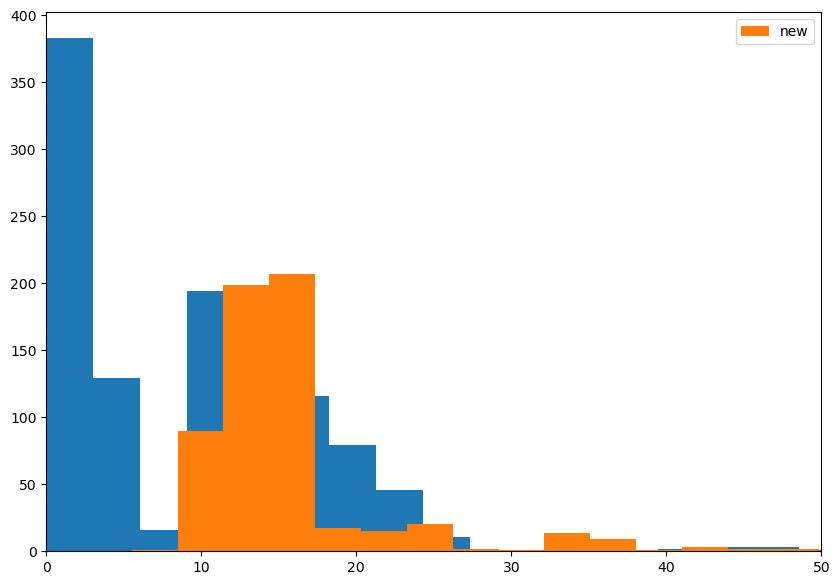

In [279]:
plt.hist(df['dist_to_implant'], bins=200)
plt.hist(newdf['dist_to_implant'], bins=200, label='new')
plt.legend()
plt.xlim(0,50)

In [306]:
len(dfs[0]), len(dfs[1])

(1268, 1268)

Text(0, 0.5, 'Counts')

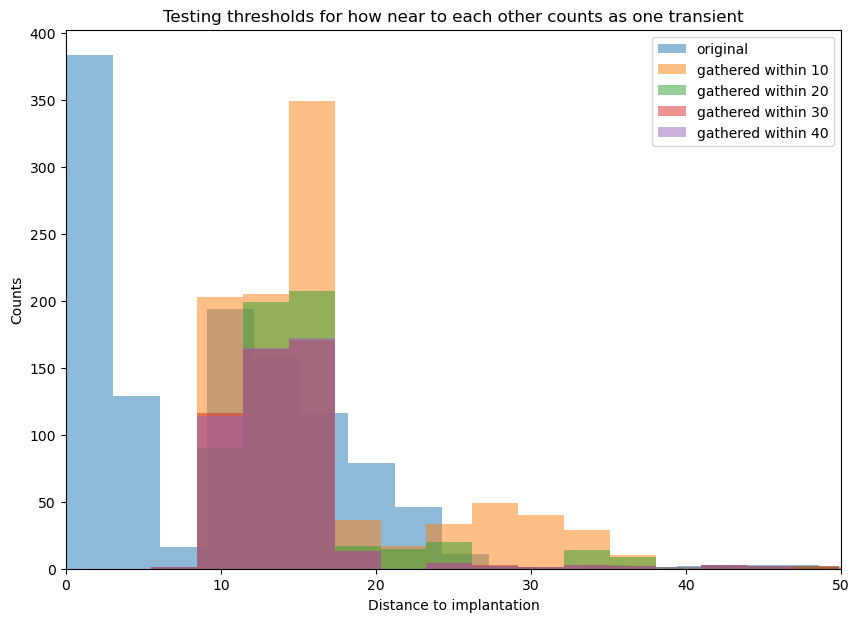

In [318]:
plt.hist(df['dist_to_implant'], bins=200, label='original', alpha=.5)
for i, newdf in enumerate(dfs[:4]):
    plt.hist(newdf['dist_to_implant'], bins=200, label='gathered within '+str(test_closenesses[i]), alpha=.5)

plt.legend()
plt.xlim(0,50)
plt.title("Testing thresholds for how near to each other counts as one transient")
plt.xlabel("Distance to implantation")
plt.ylabel("Counts")

In [269]:
get_efficiency(

(467, 800)

In [286]:
cut_len, implant_len = get_efficiency(newdf, df_implants_pos, 40, 'both')
# print(posneg, thr, len(df), cut_len, cut_len/len(df_implants_pos))
precision = pr.precision(num_true_retrieved=cut_len, num_all_retrieved=len(newdf))
# print(precision)
recall = pr.recall(num_true_retrieved=cut_len, num_all_true=len(df_implants_pos))

In [287]:
precision, recall

(0.6973293768545994, 0.5875)

In [280]:
np.sum(newdf['dist_to_implant']>30)

123

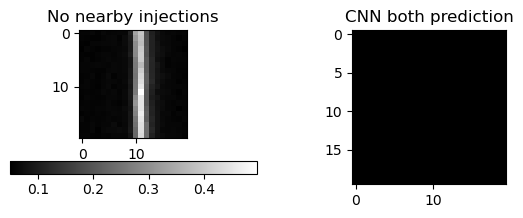

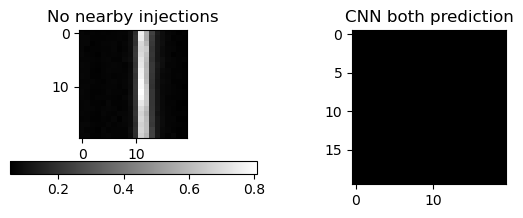

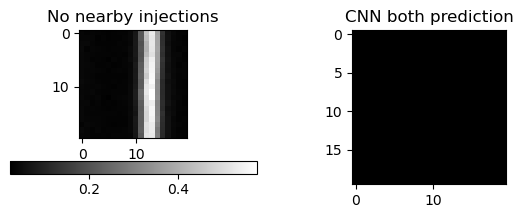

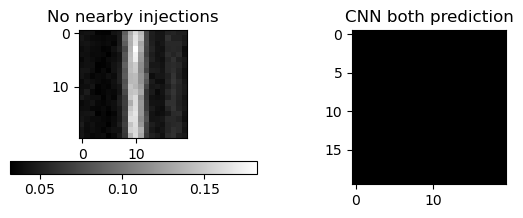

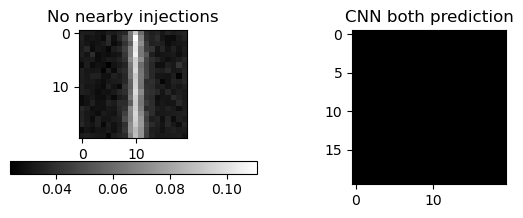

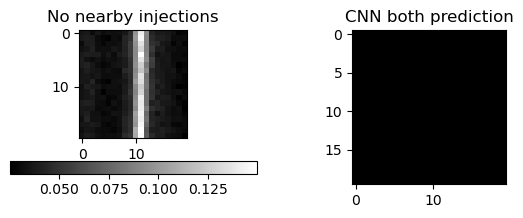

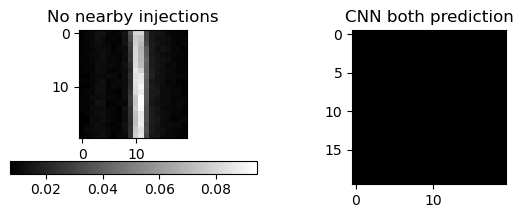

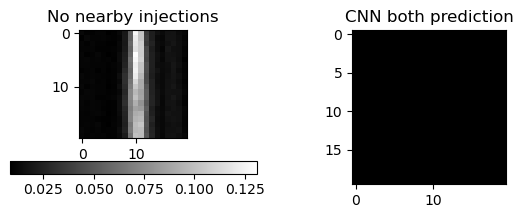

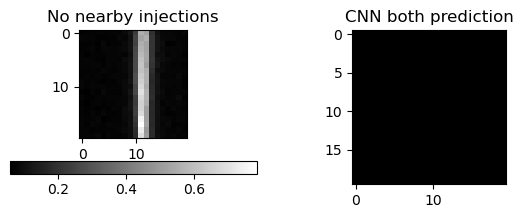

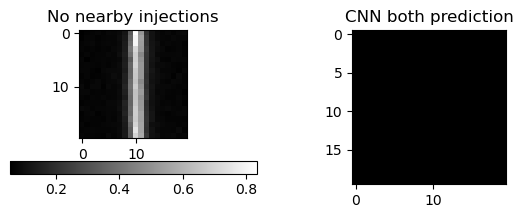

In [285]:
for index in newdf[(newdf['dist_to_implant']>40)*(newdf['dist_to_implant']<60)].index:
    rff.inspect_stamp_and_map(newdf, index, posneg='pos',neweff='nosat_eff_data/',pdirec='predsarrays_average')

In [147]:
df

,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,...,brightness_ranking,quadrant,num_in_file_in_star,dup_indices,is_smaller_dup,dist_to_implant,row_from_implant,col_from_implant,A_from_implant,sig_from_implant
0,0,0,ztf_20221020148032_000686_zg_c02_x_0001.,1,pos,38.714286,240.071429,42,250.0,1761.0,...,6,1,10.0,[],0.0,0.294508,49.0,250.0,1.50,4.0
1,1,1,ztf_20221020148032_000686_zg_c02_x_0001.,1,pos,42.061728,476.086420,81,487.0,435.0,...,1,1,12.0,[],0.0,0.942243,53.0,486.0,10.00,5.0
2,2,2,ztf_20221020148032_000686_zg_c02_x_0001.,1,pos,46.745455,1430.381818,55,1441.0,1579.0,...,2,1,6.0,[],0.0,1.398583,58.0,1441.0,1.20,5.0
3,3,3,ztf_20221020148032_000686_zg_c02_x_0001.,1,pos,71.750000,2256.916667,24,2266.0,1067.0,...,9,1,4.0,[],0.0,0.950146,82.0,2266.0,5.00,4.0
4,4,4,ztf_20221020148032_000686_zg_c02_x_0001.,1,pos,85.644068,2954.305085,59,2964.0,425.0,...,3,1,5.0,[],0.0,1.389831,97.0,2964.0,1.50,7.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1263,1263,1263,ztf_20221020294271_000449_zr_c04_x_0004.,3,neg,2376.250000,2028.350000,20,2038.0,1087.0,...,0,3,22.0,[],0.0,11.755212,2398.0,2038.0,2.00,5.0
1264,1264,1264,ztf_20221020294271_000449_zr_c04_x_0004.,3,neg,2401.161290,2028.387097,62,2038.0,1087.0,...,0,3,22.0,[],0.0,13.166982,2398.0,2038.0,2.00,5.0
1265,1265,1265,ztf_20221020294271_000449_zr_c04_x_0004.,3,neg,2455.254237,2557.593220,59,2568.0,2214.0,...,7,3,7.0,[],0.0,13.260478,2452.0,2568.0,2.00,5.0
1266,1266,1266,ztf_20221020294271_000449_zr_c04_x_0004.,3,neg,2513.800000,1150.200000,5,1161.0,296.0,...,2,3,8.0,[],0.0,71.804457,2452.0,1161.0,1.15,6.0


In [26]:
def plot_all_precision_recall_from_eff_data(test_name, df_implants_pos, df_implants_neg,spacing="new", threshes = [ "0.5","0.6","0.7","0.8","0.85","0.9","0.95", "0.98","0.99","0.999","0.9999"], subset=None, combine_transients=False, title=None):
     #["0.2","0.3","0.4","0.5","0.6","0.7",
    threshold=20
    precisions = np.zeros(len(threshes))
    recalls = np.zeros(len(threshes))
    precisions_subset = np.zeros(len(threshes))
    recalls_subset = np.zeros(len(threshes))
    
    precisions_combined = np.zeros(len(threshes))
    recalls_combined = np.zeros(len(threshes))
    # if subset!=None:
    df_implants_pos_subset = df_implants_pos[df_implants_pos['A_from_implant']>=(1+subset)]
    df_implants_neg_subset = df_implants_neg[df_implants_neg['A_from_implant']<=(1-subset)]
    for i, thr in enumerate(threshes):
        # for posneg in ["pos", "neg"]:#,"neg"]:
            df_pos = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_"+'pos'+"/predsarrays_"+test_name+"/df_matched_thr_"+thr)
            df_neg = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_"+'neg'+"/predsarrays_"+test_name+"/df_matched_thr_"+thr)

            # if combine_transients==True:
            bothpath_pos = ("/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_"+'pos'+"/df_both_matched_thr_"+thr)
                # if os.path.isfile(bothpath):
            df_pos_combined = pd.read_csv(bothpath_pos)
            bothpath_neg = ("/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_"+'neg'+"/df_both_matched_thr_"+thr)
                # if os.path.isfile(bothpath):
            df_neg_combined = pd.read_csv(bothpath_neg)
                # else: 
                #     df = make_transient_detections_df(df)
                #     df.to_csv(bothpath)
                
            
            # df_implants_pos = df_implants_pos[df_implants_pos['A_from_implant']>=(1+subset)]
            # df_implants_neg = df_implants_neg[df_implants_neg['A_from_implant']<=(1-subset)]
            ignore_mask_pos = (np.abs(df_pos['dist_to_implant'])<25)*(df_pos['A_from_implant']<(1+subset))
            ignore_mask_neg = (np.abs(df_neg['dist_to_implant'])<25)*(df_neg['A_from_implant']>(1-subset))
            # if posneg=='pos':
            df_pos_subset = df_pos[~ignore_mask_pos]

            df_neg_subset = df_neg[~ignore_mask_neg]
            
            ignore_mask_pos_combined = (np.abs(df_pos_combined['dist_to_implant'])<25)*(df_pos_combined['A_from_implant']<(1+subset))
            ignore_mask_neg_combined = (np.abs(df_neg_combined['dist_to_implant'])<25)*(df_neg_combined['A_from_implant']>(1-subset))

            df_pos_combined = df_pos_combined[~ignore_mask_pos_combined]

            df_neg_combined = df_neg_combined[~ignore_mask_neg_combined]
            # if combine_transients==True:
            newposneg = 'both'
            cut_len_pos_combined, implant_len_pos_combined = get_efficiency(df_pos_combined, df_implants_pos_subset, threshold, newposneg)
            cut_len_neg_combined, implant_len_neg_combined = get_efficiency(df_neg_combined, df_implants_neg_subset, threshold, newposneg)
            
            cut_len_pos, implant_len_pos = get_efficiency(df_pos, df_implants_pos, threshold, 'pos')
            cut_len_neg, implant_len_neg = get_efficiency(df_neg, df_implants_neg, threshold, 'neg')
            cut_len_pos_subset, implant_len_pos_subset = get_efficiency(df_pos_subset, df_implants_pos_subset, threshold, 'pos')
            cut_len_neg_subset, implant_len_neg_subset = get_efficiency(df_neg_subset, df_implants_neg_subset, threshold, 'neg')
                
            precision = pr.precision(num_true_retrieved=(cut_len_pos+cut_len_neg), num_all_retrieved=len(df_pos)+len(df_neg))
            # print(precision)
            recall = pr.recall(num_true_retrieved=(cut_len_pos+cut_len_neg), num_all_true=len(df_implants_pos)+len(df_implants_neg))
            # print(recall)
            precisions[i]=precision
            recalls[i]=recall
            
            precision_subset = pr.precision(num_true_retrieved=(cut_len_pos_subset+cut_len_neg_subset), num_all_retrieved=len(df_pos_subset)+len(df_neg_subset))
            # print(precision)
            recall_subset = pr.recall(num_true_retrieved=(cut_len_pos_subset+cut_len_neg_subset), num_all_true=len(df_implants_pos_subset)+len(df_implants_neg_subset))
            # print(recall)
            precisions_subset[i]=precision_subset
            recalls_subset[i]=recall_subset
            
            precision_combined = pr.precision(num_true_retrieved=(cut_len_pos_combined+cut_len_neg_combined), num_all_retrieved=len(df_pos_combined)+len(df_neg_combined))
            # print(precision)
            recall_combined = pr.recall(num_true_retrieved=(cut_len_pos_combined+cut_len_neg_combined), num_all_true=len(df_implants_pos_subset)+len(df_implants_neg_subset))
            # print(recall)
            precisions_combined[i]=precision_combined
            recalls_combined[i]=recall_combined

    if spacing!="thresh":
        threshes = np.array(threshes).astype(float)
    plt.plot(threshes, precisions, label="Precision, all transients", linewidth=3, c="darkmagenta", linestyle='dotted', alpha=.3)

    plt.plot(threshes, recalls, label="Recall, all transients", linewidth=3, c="darkmagenta", linestyle='dashed', alpha=.3)
    
    plt.plot(threshes, precisions_subset, label="Precision, significant transients", linewidth=3, c="darkmagenta", linestyle='dotted', alpha=.5)

    plt.plot(threshes, recalls_subset, label="Recall, significant transients", linewidth=3, c="darkmagenta", linestyle='dashed', alpha=.5)
    
    plt.plot(threshes, precisions_combined, label="Precision, significant + de-duplicated transients", linewidth=3, c="darkmagenta", linestyle='dotted')

    plt.plot(threshes, recalls_combined, label="Recall, significant + de-duplicated transients", linewidth=3, c="darkmagenta", linestyle='dashed')
    
        
    if type(threshes[0])==str:
        plt.axvline("0.99", label='chosen threshold', c='#000000')
    else:
        plt.axvline(0.99, label='Chosen threshold of 0.99', c='#000000')
    plt.legend(fontsize=16)
    if title==None:
        plt.title(
        "Precision and Recall Curves from Eff Data for Brightening and Dimming Transients: "+test_name+", with subset >"+str(subset), fontsize=18)
    else:
        plt.title(title, fontsize=18)
    plt.xlabel("Threshold", fontsize=18)
    plt.ylabel("Precision and Recall", fontsize=18)
    
    # plt.ylim(0.15, 1.01)
    plt.tick_params(axis="both", labelsize=18)
    plt.show()
    # return precisions_pos, recalls_pos, precisions_neg, recalls_neg

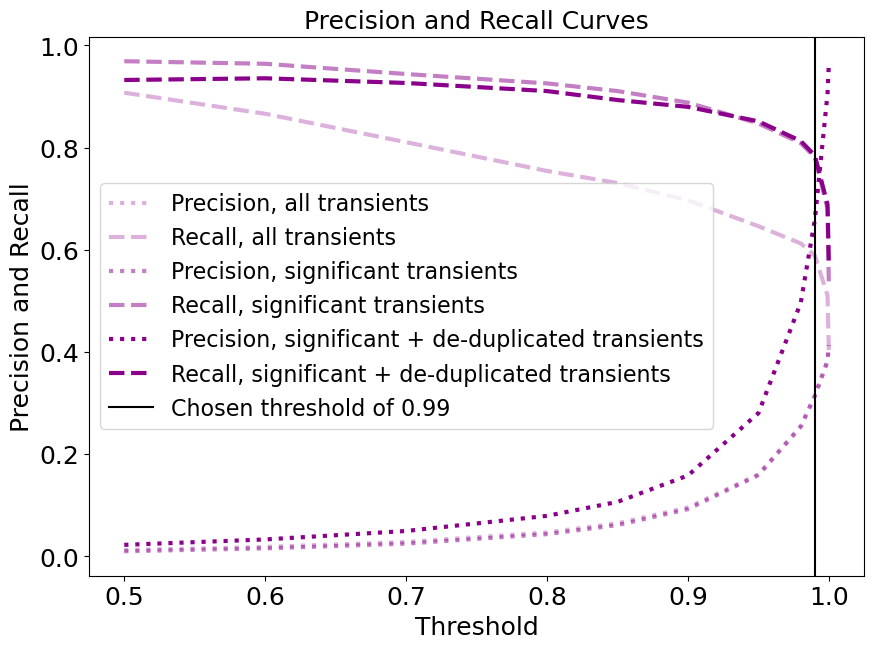

In [27]:
plot_all_precision_recall_from_eff_data("average", df_implants_pos, df_implants_neg,spacing='new', subset=.1, title='Precision and Recall Curves')
# plot_precision_recall_from_eff_data("average", df_implants_pos, df_implants_neg,spacing='new', subset=.1, title='Precision and Recall Curves', combine_transients=True)

In [136]:
def stamp_and_map(df, index, eff=True, neweff="nosat_eff_data/", posneg=None, size=10, column=None, nn_or_imp="nn", thr=True, varthresh=.9999,star=False, direcname='1020', pdirec="predsarrays"):
    '''
    for efficiency data
    '''
    wid = 10
    if column!=None:
        index = df[df[column]==index].index[0]
    if eff==True:
        if posneg==None:
            posneg = df.loc[index, "type"]
            print("Need posneg if you want to see the correct pimg...")
        if posneg=="pos":
            extension = "_1_implanted_pos.npy"
            if neweff=="new_eff_data/" or neweff=="nosat_eff_data/":
                extension = "_"+str(df.loc[index, "quad"])+".npy"
            
            fpath = '/lustre/lrspec/ZTF_data/efficiency_testing/'+neweff+'full_image_implantations_pos/images/'
            ppath = "/lustre/lrspec/ZTF_data/efficiency_testing/"+neweff+"full_image_implantations_pos/"+pdirec+"/"

        elif posneg=="neg":
            extension = "_1_implanted_neg.npy"
            if neweff=="new_eff_data/" or neweff=="nosat_eff_data/":
                extension = "_"+str(df.loc[index, "quad"])+".npy"
            
            fpath = '/lustre/lrspec/ZTF_data/efficiency_testing/'+neweff+'full_image_implantations_neg/images/'
            ppath = "/lustre/lrspec/ZTF_data/efficiency_testing/"+neweff+"full_image_implantations_neg/"+pdirec+"/"
        
        else:
            print("POSNEG ISSUE")
        fname = df.loc[index]["filename"] + extension
    else:
        posneg = df.loc[index, 'type']

    # if nn_or_imp=="nn":
    #     fig, ax = plt.subplots(1, 2, figsize=(7,2))
    if thr==None:
        fig, ax = plt.subplots(1, 4, figsize=(10,2))
    
    # print(df.iloc[index]["filename"])
    if nn_or_imp == "nn":
        row = int(df.loc[index]["row_from_nn"])+wid
        col = int(df.loc[index]["col_from_nn"])+wid
    elif nn_or_imp == "imp":
        row = int(df.loc[index]["col_from_implant"])
        col = int(df.loc[index]["row_from_implant"])
        
    if eff:
        path = fpath + fname 
        array = np.load(path)
        imj = ax[0].imshow(
                    
                        array[
                            row - size : row + size ,
                            col  - size : col  + size,
                        ].T
                    
                    )
    else:
        imj = ax[0].imshow(sobels_to_array(df.loc[index, 'stamp']))
                    
    nrow, ncol = 3080, 3072 
    if eff==True:
        if pdirec=="predsarrays":
            if posneg =="pos":
                pfile = df.loc[index]["filename"]+"_extraction_predsarray_pos_predsarray.npy"
                predsarray = np.load(ppath+pfile)
                if df.loc[index, "type"]=="pos":
                    pimg = predsarray[:, 1].reshape(ncol - 2 * wid, nrow - 2 * wid)
                else:
                    pimg = predsarray[:, 2].reshape(ncol - 2 * wid, nrow - 2 * wid)
            elif posneg=="neg":
                pfile = df.loc[index]["filename"]+"_extraction_predsarray_neg_predsarray.npy"
                predsarray = np.load(ppath+pfile)
                if df.loc[index, "type"]=="pos":
                    pimg = predsarray[:, 1].reshape(ncol - 2 * wid, nrow - 2 * wid)
                else:
                    pimg = predsarray[:, 2].reshape(ncol - 2 * wid, nrow - 2 * wid)
        else:
            pfile = df.loc[index]["filename"]+"_extraction_predsarray_1_predsarray.npy"
            if neweff=="new_eff_data/" or neweff=="nosat_eff_data/":
                pfile = df.loc[index]["filename"]+"_" + str(df.loc[index]["quad"])+"_predsarray.npy"
            predsarray = np.load(ppath+pfile)
            if df.loc[index, "type"]=="pos":
                pimg = predsarray[:, 1].reshape(ncol - 2 * wid, nrow - 2 * wid)
            else:
                pimg = predsarray[:, 2].reshape(ncol - 2 * wid, nrow - 2 * wid)
    else:      
        path = '/lustre/lrspec/ZTF_data/science_extractions/'+direcname+'/'
        pred = df.loc[index]["filename"]
        extra = '_extraction_predsarray_'+str(df.loc[index,'quad'])+'_predsarray.npy'
        print(path+pred+extra)
        predsarray = np.load(path+pred+extra)
        if df.loc[index, "type"]=="pos":
            pimg = predsarray[:, 1].reshape(ncol - 2 * wid, nrow - 2 * wid)
        # else:
    pimg_neg = predsarray[:, 2].reshape(ncol - 2 * wid, nrow - 2 * wid)





    if thr:
        ax[1].imshow(
        
                    pimg[
                        col - size  - wid : col + size - wid,
                        row  - size - wid: row  + size - wid,
                    ]>varthresh
                )
    else:
        ax[1].imshow(
        
                    pimg[
                        col - size  - wid: col + size - wid,
                        row  - size - wid: row  + size - wid,
                    ], cmap='copper'
                )
        ax[2].imshow(
        
                    pimg_neg[
                        col - size  - wid: col + size - wid,
                        row  - size - wid: row  + size - wid,
                    ], cmap='bone', vmax=1.3
                )
        ax[2].set_title("CNN \nDimming Prediction")
        ax[3].imshow(
        
                    pimg[
                        col - size  - wid: col + size - wid,
                        row  - size - wid : row  + size - wid,
                    ]>varthresh, cmap='copper'
                )
        layer = pimg_neg[
                        col - size  - wid: col + size - wid,
                        row  - size - wid: row  + size - wid,
                    ]
        masked = np.ma.masked_where(layer <=.99, layer)
        # ax.imshow(masked,alpha=1,cmap = 'Reds')
        # plt.show()
        ax[3].imshow(masked,alpha=1, cmap='bone', zorder=10, vmin=0, vmax=1.3
                )
        ax[3].set_title("CNN Prediction \nThresholded at 0.99")
    if star==True:
                    starpos = df.loc[index]['closest_x']
                    ax[0].scatter(starpos- (col - size  + wid), 10)
#     pfile_pos = df.iloc[index]["filename"]+"_extraction_predsarray_pos_predsarray.npy"
#     predsarray_pos = np.load(ppath+pfile_pos)
#     pimg_pos = predsarray_pos[:, 1].reshape(ncol - 2 * wid, nrow - 2 * wid)
#     pfile_neg = df.iloc[index]["filename"]+"_extraction_predsarray_neg_predsarray.npy"
#     predsarray_neg = np.load(ppath+pfile_neg)
#     pimg_neg = predsarray_neg[:, 2].reshape(ncol - 2 * wid, nrow - 2 * wid)
#     ax[1].imshow(
        
#                     pimg_neg[
#                         col - size : col + size,
#                         row  - size : row  + size,
#                     ].T>.9999
#                 )
#     ax[2].imshow(pimg_pos[
#                         col - size : col + size,
#                         row  - size : row  + size,
#                     ].T>.9999
#                 ) 
    if eff==True:
        ax[0].annotate(
        "Injection",
        xy=(  df["row_from_implant"].loc[index]-col+size,df["col_from_implant"].loc[index]-row+size),
        xytext=(size+3*size/4, size/2),  
        arrowprops=dict(
            facecolor="red",
            edgecolor="red",
            # shrink=1.0,
            # headlength=5,
            # headwidth=3,
        ),
        color="white",
        fontsize=10,
        ha="center",
        # va="top",
        rotation=0,
        zorder=10,
    )
        if np.abs(df['dist_to_implant'].loc[index])<30:
            ax[0].set_title("Injected \nBrightening Transient")#, Index "+str(index)+ ", A = "+str(df["A_from_implant"].loc[index])+", sig = "+str(df["sig_from_implant"].loc[index]))
        else:
            ax[0].set_title("No nearby injections")
    else:
        ax[0].set_title("Injected image, Index "+str(index))
        
    # ax[1].set_title("CNN "+str(df.loc[index, "type"])+" prediction")
    ax[1].set_title("CNN \nBrightening Prediction")
    # ax[2].set_title("CNN pos prediction")
    # print(df["row_from_implant"].iloc[index], col, df["col_from_implant"].iloc[index], row)
    # fig.colorbar(imj, orientation='horizontal')
    for axis in ax:
        axis.set_xticks([])
        axis.set_yticks([])
    plt.show()

In [46]:
df[(df['A_from_implant']==2)*(df['dist_to_implant']<3)]

,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,...,brightness_ranking,quadrant,num_in_file_in_star,dup_indices,is_smaller_dup,dist_to_implant,row_from_implant,col_from_implant,A_from_implant,sig_from_implant
5,5,5,ztf_20221020148032_000686_zg_c02_x_0001.,1,pos,101.303030,2245.070707,99,2255.0,1346.0,...,0,1,4.0,[],0.0,1.698442,113.0,2255.0,2.0,9.0
23,23,23,ztf_20221020148032_000686_zg_c02_x_0001.,1,pos,2371.411765,1431.470588,85,1441.0,1579.0,...,2,1,6.0,[],0.0,0.753309,2382.0,1441.0,2.0,5.0
82,82,82,ztf_20221020138241_000686_zi_c05_x_0000.,4,pos,1809.333333,2554.510417,96,2565.0,616.0,...,2,4,10.0,[],0.0,1.737087,1821.0,2565.0,2.0,7.0
84,84,84,ztf_20221020138241_000686_zi_c05_x_0000.,4,pos,1846.742574,2075.475248,101,2085.0,886.0,...,4,4,9.0,[],0.0,1.344239,1858.0,2085.0,2.0,7.0
95,95,95,ztf_20221020138241_000686_zi_c05_x_0000.,4,pos,2375.367647,2075.029412,68,2085.0,886.0,...,4,4,9.0,[],0.0,0.633037,2386.0,2085.0,2.0,4.0
156,156,156,ztf_20221020148032_000686_zg_c02_x_0001.,3,pos,638.747573,1065.485437,103,1075.0,2282.0,...,7,3,7.0,[],0.0,2.310455,651.0,1076.0,2.0,8.0
160,160,160,ztf_20221020148032_000686_zg_c02_x_0001.,3,pos,1206.731183,432.118280,93,442.0,2423.0,...,6,3,11.0,[],0.0,1.274318,1218.0,442.0,2.0,6.0
162,162,162,ztf_20221020148032_000686_zg_c02_x_0001.,3,pos,1214.830357,503.500000,112,514.0,1881.0,...,8,3,12.0,[],0.0,2.226511,1227.0,513.0,2.0,9.0
234,234,234,ztf_20221020148032_000686_zg_c02_x_0001.,2,pos,602.163934,649.483607,122,660.0,1491.0,...,1,2,8.0,[],0.0,2.882695,615.0,660.0,2.0,9.0
254,254,254,ztf_20221020148032_000686_zg_c02_x_0001.,2,pos,1807.000000,1528.635135,74,1644.0,2227.0,...,24,2,8.0,[],0.0,1.064484,1818.0,1539.0,2.0,6.0


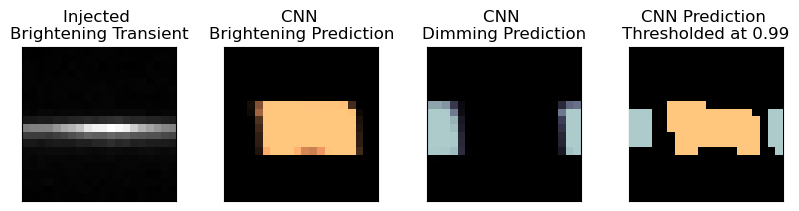

In [137]:
# for index in dfs_pos["sat_nnbigger_nopool"][dfs_pos["sat_nnbigger_nopool"]['Diff']>10].index[0]:
stamp_and_map(df, 95, posneg='pos', neweff="nosat_eff_data/",pdirec='predsarrays_average', thr=None, varthresh=.99)

In [145]:
len(df_implants_neg)

800

In [143]:
np.unique(df_implants_pos['A_from_implant'], return_counts=True)

(array([ 1.005,  1.01 ,  1.05 ,  1.1  ,  1.15 ,  1.2  ,  1.3  ,  1.4  ,
         1.5  ,  2.   ,  5.   ,  7.   , 10.   ]),
 array([62, 61, 61, 61, 61, 62, 62, 62, 62, 61, 61, 62, 62]))

In [147]:
df = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_pos/predsarrays_average/df_matched_thr_0.99")

In [151]:
cut_len, implant_len = get_efficiency(df, df_implants_pos, 20, 'pos')
pr.precision(num_true_retrieved=cut_len, num_all_retrieved=len(df))


0.36198738170347006

In [152]:
pr.recall(num_true_retrieved=cut_len, num_all_true=implant_len)

0.57375

In [153]:
df_neg = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_neg/predsarrays_average/df_matched_thr_0.99")

In [154]:
cut_len, implant_len = get_efficiency(df, df_implants_neg, 20, 'neg')
pr.precision(num_true_retrieved=cut_len, num_all_retrieved=len(df))


0.2586750788643533

In [155]:
pr.recall(num_true_retrieved=cut_len, num_all_true=implant_len)

0.41

In [159]:
if 1==1:
    threshes = ["0.99"]
    subset=.1
    test_name="average"
    threshold=20
    precisions = np.zeros(len(threshes))
    recalls = np.zeros(len(threshes))
    precisions_subset = np.zeros(len(threshes))
    recalls_subset = np.zeros(len(threshes))
    
    precisions_combined = np.zeros(len(threshes))
    recalls_combined = np.zeros(len(threshes))
    # if subset!=None:
    df_implants_pos_subset = df_implants_pos[df_implants_pos['A_from_implant']>=(1+subset)]
    df_implants_neg_subset = df_implants_neg[df_implants_neg['A_from_implant']<=(1-subset)]
    for i, thr in enumerate(threshes):
        # for posneg in ["pos", "neg"]:#,"neg"]:
            df_pos = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_"+'pos'+"/predsarrays_"+test_name+"/df_matched_thr_"+thr)
            df_neg = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_"+'neg'+"/predsarrays_"+test_name+"/df_matched_thr_"+thr)

            # if combine_transients==True:
            bothpath_pos = ("/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_"+'pos'+"/df_both_matched_thr_"+thr)
                # if os.path.isfile(bothpath):
            df_pos_combined = pd.read_csv(bothpath_pos)
            bothpath_neg = ("/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_"+'neg'+"/df_both_matched_thr_"+thr)
                # if os.path.isfile(bothpath):
            df_neg_combined = pd.read_csv(bothpath_neg)
                # else: 
                #     df = make_transient_detections_df(df)
                #     df.to_csv(bothpath)
                
            
            # df_implants_pos = df_implants_pos[df_implants_pos['A_from_implant']>=(1+subset)]
            # df_implants_neg = df_implants_neg[df_implants_neg['A_from_implant']<=(1-subset)]
            ignore_mask_pos = (np.abs(df_pos['dist_to_implant'])<25)*(df_pos['A_from_implant']<(1+subset))
            ignore_mask_neg = (np.abs(df_neg['dist_to_implant'])<25)*(df_neg['A_from_implant']>(1-subset))
            # if posneg=='pos':
            df_pos_subset = df_pos[~ignore_mask_pos]

            df_neg_subset = df_neg[~ignore_mask_neg]
            
            ignore_mask_pos_combined = (np.abs(df_pos_combined['dist_to_implant'])<25)*(df_pos_combined['A_from_implant']<(1+subset))
            ignore_mask_neg_combined = (np.abs(df_neg_combined['dist_to_implant'])<25)*(df_neg_combined['A_from_implant']>(1-subset))

            df_pos_combined = df_pos_combined[~ignore_mask_pos_combined]

            df_neg_combined = df_neg_combined[~ignore_mask_neg_combined]
            # if combine_transients==True:
            newposneg = 'both'
            cut_len_pos_combined, implant_len_pos_combined = get_efficiency(df_pos_combined, df_implants_pos_subset, threshold, newposneg)
            cut_len_neg_combined, implant_len_neg_combined = get_efficiency(df_neg_combined, df_implants_neg_subset, threshold, newposneg)
            
            cut_len_pos, implant_len_pos = get_efficiency(df_pos, df_implants_pos, threshold, 'pos')
            cut_len_neg, implant_len_neg = get_efficiency(df_neg, df_implants_neg, threshold, 'neg')
            cut_len_pos_subset, implant_len_pos_subset = get_efficiency(df_pos_subset, df_implants_pos_subset, threshold, 'pos')
            cut_len_neg_subset, implant_len_neg_subset = get_efficiency(df_neg_subset, df_implants_neg_subset, threshold, 'neg')
                
            precision = pr.precision(num_true_retrieved=(cut_len_pos+cut_len_neg), num_all_retrieved=len(df_pos)+len(df_neg))
            # print(precision)
            recall = pr.recall(num_true_retrieved=(cut_len_pos+cut_len_neg), num_all_true=len(df_implants_pos)+len(df_implants_neg))
            # print(recall)
            precisions[i]=precision
            recalls[i]=recall
            
            precision_subset = pr.precision(num_true_retrieved=(cut_len_pos_subset+cut_len_neg_subset), num_all_retrieved=len(df_pos_subset)+len(df_neg_subset))
            # print(precision)
            recall_subset = pr.recall(num_true_retrieved=(cut_len_pos_subset+cut_len_neg_subset), num_all_true=len(df_implants_pos_subset)+len(df_implants_neg_subset))
            # print(recall)
            precisions_subset[i]=precision_subset
            recalls_subset[i]=recall_subset
            
            precision_combined = pr.precision(num_true_retrieved=(cut_len_pos_combined+cut_len_neg_combined), num_all_retrieved=len(df_pos_combined)+len(df_neg_combined))
            # print(precision)
            recall_combined = pr.recall(num_true_retrieved=(cut_len_pos_combined+cut_len_neg_combined), num_all_true=len(df_implants_pos_subset)+len(df_implants_neg_subset))
            # print(recall)
            precisions_combined[i]=precision_combined
            recalls_combined[i]=recall_combined

In [167]:
print(pr.precision(num_true_retrieved=cut_len_pos_combined, num_all_retrieved=len(df_pos_combined)),
      pr.recall(num_true_retrieved=(cut_len_pos_combined), num_all_true=len(df_implants_pos_subset)),
pr.precision(num_true_retrieved=cut_len_neg_combined, num_all_retrieved=len(df_neg_combined)),
# print(precision)
      
                  
pr.recall(num_true_retrieved=(cut_len_neg_combined), num_all_true=len(df_implants_neg_subset))
                  )
      

0.8006993006993007 0.7435064935064936 0.5644028103044496 0.8281786941580757


In [160]:
recalls_combined

array([0.78464107])